# 03 Labels, splits and window audit (Phase 3)

Battery SOH nowcast from a partial discharge window, MATR fast-charge data (140 raw A123 LFP cells).
This phase does data-quality triage, masks, labels, reference curves, policy groups, splits, window audit, canaries and automated leakage tests.
No models (only the one-variable linear canaries of section 7), no scaling, no ONNX, no raw-file access, no installs.
Allowed writes: `data/processed`, `data/processed/splits`, `outputs/phase3`, `outputs/phase3/figures`, `src/soh_common.py`.

In [1]:
import os, sys, json, time, types, hashlib, warnings, traceback, contextlib, math, re, itertools
from pathlib import Path
import numpy as np
import pandas as pd
import psutil
import matplotlib
import matplotlib.pyplot as plt
try:
    from tqdm.auto import tqdm
except Exception:
    def tqdm(x, **k):
        return x

T0 = time.time()
warnings.filterwarnings("ignore", category=FutureWarning)

# ---- config
SEED = 42
NOMINAL_AH = 1.1
EOL_AH = 0.88
REF_FIRST_CYCLE = 8
REF_N = 5
SCORE_GAP = 8
MIN_SCORE_CYCLE = 20
CANARY_R2 = 0.98
LATE_WINDOW_L = 0.60
MONO_TOL = 5e-3
Q0_TOL = 0.01
V_STEP = 0.0015015

# ---- paths
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
PROC = ROOT / "data/processed"
SPL = PROC / "splits"
P2 = ROOT / "outputs/phase2"
OUT = ROOT / "outputs/phase3"
FIG = OUT / "figures"
SRC = ROOT / "src"
for d in (PROC, SPL, OUT, FIG, SRC):  # only allowed write locations are created
    d.mkdir(parents=True, exist_ok=True)

# ---- check / error bookkeeping (nothing is swallowed silently)
CHECKS, ERRORS = [], []

def check(name, passed, detail=""):
    """passed: bool, or one of 'PASS'/'WARN'/'FAIL'."""
    status = passed if isinstance(passed, str) else ("PASS" if passed else "FAIL")
    assert status in ("PASS", "WARN", "FAIL"), status
    CHECKS.append({"name": name, "status": status, "detail": str(detail)})
    print(f"[{status}] {name}" + (f" -- {detail}" if str(detail) else ""))
    return status == "PASS"

def warn_if(name, ok, detail=""):
    return check(name, "PASS" if ok else "WARN", detail)

@contextlib.contextmanager
def guard(label):
    """Record any exception as a FAIL plus an error entry, then continue."""
    try:
        yield
    except Exception as e:
        tb = traceback.format_exc()
        ERRORS.append({"section": label, "error": repr(e), "traceback": tb})
        check(f"error in {label}", "FAIL", repr(e))
        print(tb)

def ram_check(tag=""):
    avail = psutil.virtual_memory().available / 2**30
    if avail < 2.0:
        check(f"RAM available {tag}", "WARN", f"{avail:.2f} GiB < 2 GiB")
    return avail

def sha256_file(path, chunk=8 * 2**20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while True:
            b = f.read(chunk)
            if not b:
                break
            h.update(b)
    return h.hexdigest()

def ranges(nums):
    """Compact integer ranges: [1,2,3,7] -> '1-3, 7'."""
    nums = sorted({int(n) for n in nums})
    if not nums:
        return ""
    out, s, p = [], nums[0], nums[0]
    for n in nums[1:]:
        if n == p + 1:
            p = n
            continue
        out.append(f"{s}-{p}" if p > s else f"{s}")
        s = p = n
    out.append(f"{s}-{p}" if p > s else f"{s}")
    return ", ".join(out)

def save_csv(df, name, index=False):
    p = OUT / name
    df.to_csv(p, index=index)
    return p

print("ROOT", ROOT)
print("python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__)
import sklearn, scipy
print("scikit-learn", sklearn.__version__, "| scipy", scipy.__version__)
print(f"RAM total {psutil.virtual_memory().total/2**30:.1f} GiB, available {ram_check('start'):.1f} GiB")

c:\workstation\3RD YEAR\Battery-Health-Estimation\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


ROOT c:\workstation\3RD YEAR\Battery-Health-Estimation
python 3.13.13 | numpy 2.5.4 | pandas 3.1.0
scikit-learn 1.9.1 | scipy 1.18.1
RAM total 15.7 GiB, available 6.0 GiB


In [2]:
# Single source of truth for src/soh_common.py. It is exec'd here for use in this notebook
# and written to disk in section 10 (the written file is re-imported and cross-checked).
SOH_COMMON_SRC = r'''"""Shared constants and helpers for the battery SOH nowcast project (written by Phase 3)."""
from pathlib import Path
import numpy as np
import pandas as pd

SEED = 42
NOMINAL_AH = 1.1
EOL_AH = 0.88
REF_FIRST_CYCLE = 8
REF_N = 5
SCORE_GAP = 8
MIN_SCORE_CYCLE = 20
CANARY_R2 = 0.98
LATE_WINDOW_L = 0.60
V_TOP = 3.5
V_STEP = 0.0015015
N_GRID = 1000
KNOT_VOLTAGES = tuple(round(3.5 - 0.1 * i, 1) for i in range(16))


def get_root(cwd=None):
    root = Path(cwd) if cwd is not None else Path.cwd()
    return root.parent if root.name == "notebooks" else root


def paths(root=None):
    root = get_root(root) if root is None or isinstance(root, (str, Path)) else root
    proc = root / "data/processed"
    return {
        "ROOT": root, "PROC": proc, "SPL": proc / "splits",
        "P2": root / "outputs/phase2", "OUT": root / "outputs/phase3",
        "FIG": root / "outputs/phase3/figures", "SRC": root / "src",
    }


def load_tables(root=None, mmap=True):
    """Return (cycles, qdlin, t_knots, registry); qdlin is memory-mapped float32."""
    p = paths(root)["PROC"]
    cycles = pd.read_parquet(p / "cycles_table.parquet")
    qdlin = np.load(p / "qdlin_f32.npy", mmap_mode="r" if mmap else None)
    t_knots = np.load(p / "t_knots_f32.npy")
    registry = pd.read_csv(p / "cell_registry_final.csv")
    return cycles, qdlin, t_knots, registry


def grid_index(voltage):
    """Grid index of voltage V on the 1000-point 3.5 -> 2.0 V grid (int or int array)."""
    v = np.asarray(voltage, dtype=float)
    idx = np.rint((V_TOP - v) / V_STEP).astype(int)
    if np.any(idx < 0) or np.any(idx > N_GRID - 1):
        raise ValueError(f"voltage outside the 3.5 -> 2.0 V grid: {voltage}")
    return int(idx) if idx.ndim == 0 else idx


def window_slice(open_v, close_v):
    """Slice covering grid points from open_v to close_v inclusive."""
    i_open, i_close = grid_index(open_v), grid_index(close_v)
    if i_close <= i_open:
        raise ValueError("close voltage must be below open voltage")
    return slice(i_open, i_close + 1)


# role in {primary, ablation, oracle, banned, label}; available_at says when the value exists
ALLOWLIST = {
    "dq_window":   {"role": "primary",  "available_at": "window close", "note": "build_delta_q(Qdlin, Qref, i_open, i_close)"},
    "q0":          {"role": "primary",  "available_at": "after reference cycle", "note": "median qd_sum over reference cycles"},
    "qref":        {"role": "primary",  "available_at": "after reference cycle", "note": "median Qdlin over reference cycles"},
    "cycle_number": {"role": "ablation", "available_at": "window close", "note": "index ablation"},
    "ir":          {"role": "ablation", "available_at": "end of charge", "note": "internal resistance; ablation only"},
    "chargetime":  {"role": "ablation", "available_at": "end of charge", "note": "ablation only"},
    "tavg":        {"role": "ablation", "available_at": "end of discharge", "note": "cycle summary; not available at window close"},
    "tmin":        {"role": "ablation", "available_at": "end of discharge", "note": "cycle summary; not available at window close"},
    "tmax":        {"role": "ablation", "available_at": "end of discharge", "note": "cycle summary; not available at window close"},
    "qd_sum":      {"role": "label",    "available_at": "end of discharge", "note": "summary discharge capacity; SOH label source"},
    "qd_end":      {"role": "label",    "available_at": "end of discharge", "note": "end-of-discharge capacity; label cross-check"},
    "soh_nom":     {"role": "label",    "available_at": "end of discharge", "note": "qd_sum / 1.1"},
    "soh_rel":     {"role": "label",    "available_at": "end of discharge", "note": "qd_sum / q0"},
    "soh_nom_repaired": {"role": "label", "available_at": "end of discharge", "note": "offline training use only"},
    "qc_sum":      {"role": "banned",   "available_at": "end of charge", "note": "charge capacity is a near-label proxy (baseline B5)"},
    "qc_end":      {"role": "banned",   "available_at": "end of charge", "note": "charge capacity is a near-label proxy (baseline B5)"},
    "qd_lag1":     {"role": "oracle",   "available_at": "end of previous discharge", "note": "reference baseline only; not capacity-free"},
    "window_capacity": {"role": "oracle", "available_at": "window close", "note": "Qdlin[close]-Qdlin[open]; scalar canary"},
    "cell_id":     {"role": "banned",   "available_at": "any", "note": "identifier"},
    "batch":       {"role": "banned",   "available_at": "any", "note": "batch identity leaks the test split"},
    "policy_norm": {"role": "banned",   "available_at": "any", "note": "grouping key only"},
}


def assert_allowed(columns, allowlist=None, roles=("primary", "ablation")):
    """Raise ValueError on any unknown column or any column whose role is not in `roles`."""
    al = ALLOWLIST if allowlist is None else allowlist
    cols = list(columns)
    unknown = [c for c in cols if c not in al]
    wrong = [c for c in cols if c in al and al[c]["role"] not in roles]
    if unknown or wrong:
        raise ValueError(f"disallowed input columns: unknown={unknown} wrong_role={wrong}")
    return True


def build_delta_q(qdlin_row, qref, i_open, i_close, n_points=None):
    """Window delta-Q: (Q(V) - Q(V_open)) - (Qref(V) - Qref(V_open)) on grid [i_open, i_close].

    Works on a single 1000-vector or an (n, 1000) block. Uses only values at or before the
    window close and the per-cell reference curve. n_points optionally subsamples uniformly.
    """
    q = np.asarray(qdlin_row, dtype=np.float32)[..., i_open:i_close + 1]
    r = np.asarray(qref, dtype=np.float32)[..., i_open:i_close + 1]
    dq = (q - q[..., :1]) - (r - r[..., :1])
    if n_points is not None:
        idx = np.rint(np.linspace(0, dq.shape[-1] - 1, n_points)).astype(int)
        dq = dq[..., idx]
    return dq.astype(np.float32)


def shuffle_labels_within_cell(df, seed, label_col="soh_nom", cell_col="cell_id"):
    """Phase 4 canary helper: permute labels among the rows of each cell (breaks input-label link)."""
    rng = np.random.default_rng(seed)
    out = df.copy()
    arr = out[label_col].to_numpy().copy()
    for _, idx in out.groupby(cell_col).indices.items():
        idx = np.asarray(idx)
        arr[idx] = rng.permutation(arr[idx])
    out[label_col] = arr
    return out
'''
sc = types.ModuleType("soh_common_nb")
exec(SOH_COMMON_SRC, sc.__dict__)
print("soh_common source loaded in-notebook:", len(SOH_COMMON_SRC), "chars")

soh_common source loaded in-notebook: 6343 chars


## 1. Setup and guards

Load the Phase 2 tables, verify shapes and counts, hash every Phase 2 input, then run one streaming pass over `qdlin_f32.npy` (memory-mapped, one cell at a time, float32). The pass produces per-row curve statistics and a compact column block that later sections reuse so the 420 MB array is read only once.

In [3]:
import pyarrow.parquet as pq

EXPECT_ROWS, EXPECT_CELLS, EXPECT_KEPT, EXPECT_SENS = 104_971, 129, 124, 5
INPUTS = {
    "cycles_table.parquet": PROC / "cycles_table.parquet",
    "qdlin_f32.npy": PROC / "qdlin_f32.npy",
    "t_knots_f32.npy": PROC / "t_knots_f32.npy",
    "cell_registry_final.csv": PROC / "cell_registry_final.csv",
}
missing = [k for k, p in INPUTS.items() if not p.exists()]
if missing:
    raise FileNotFoundError(f"Phase 2 inputs missing in {PROC}: {missing}")
warn_if("outputs/phase2 folder present", P2.exists(), str(P2))

print(pq.read_schema(INPUTS["cycles_table.parquet"]))
cycles = pd.read_parquet(INPUTS["cycles_table.parquet"])
qd = np.load(INPUTS["qdlin_f32.npy"], mmap_mode="r")
tk = np.load(INPUTS["t_knots_f32.npy"])
registry = pd.read_csv(INPUTS["cell_registry_final.csv"])
print("cycles", cycles.shape, "| qdlin", qd.shape, qd.dtype, "| t_knots", tk.shape, tk.dtype, "| registry", registry.shape)

REQ_CYC = ["row_id", "cell_id", "batch", "pos", "cycle_number", "placeholder", "segment", "pos_src",
           "qd_sum", "qc_sum", "qd_end", "qc_end", "ir", "n_samples", "i_dis_median", "qdlin_len", "len_mismatch",
           "flag_placeholder", "flag_qdlin_bad", "flag_diag_suspect", "flag_ir_nonpos", "flag_qd_mismatch",
           "flag_qdqc_gap", "flag_qd_spike"]
REQ_REG = ["cell_id", "status", "policy_str", "policy_norm", "cycle_life_final", "n_cycles"]
miss_c = [c for c in REQ_CYC if c not in cycles.columns]
miss_r = [c for c in REQ_REG if c not in registry.columns]
if miss_c or miss_r:
    raise KeyError(f"required columns missing: cycles_table={miss_c} registry={miss_r}. Stop and fix Phase 2 outputs.")

check("cycles_table row count", len(cycles) == EXPECT_ROWS, f"{len(cycles)} (expected {EXPECT_ROWS})")
check("cycles_table cell count", cycles.cell_id.nunique() == EXPECT_CELLS, f"{cycles.cell_id.nunique()} (expected {EXPECT_CELLS})")
check("qdlin shape/dtype", qd.shape == (EXPECT_ROWS, 1000) and qd.dtype == np.float32, f"{qd.shape} {qd.dtype}")
check("t_knots shape", tk.shape == (EXPECT_ROWS, 16), str(tk.shape))
check("row_id equals npy row order", np.array_equal(cycles["row_id"].to_numpy(), np.arange(len(cycles))),
      "row_id == arange(n)")

def as_bool(s):
    return s.fillna(False).astype(bool).to_numpy()

PH = as_bool(cycles["placeholder"]) | as_bool(cycles["flag_placeholder"])
qd_sum = cycles["qd_sum"].to_numpy(dtype=np.float64)
check("qd_sum finite for all non-placeholder rows", bool(np.isfinite(qd_sum[~PH]).all()),
      f"{int((~np.isfinite(qd_sum[~PH])).sum())} non-finite; placeholder rows {int(PH.sum())}")

# registry bookkeeping
registry["batch_i"] = registry["cell_id"].str.extract(r"^b(\d+)c")[0].astype(float)
print(registry["status"].value_counts(dropna=False).to_string())
tab_cells = list(dict.fromkeys(cycles["cell_id"]))          # file order of first appearance
reg_t = registry[registry.cell_id.isin(tab_cells)].copy()
check("all table cells are in the registry", len(reg_t) == len(tab_cells), f"{len(reg_t)}/{len(tab_cells)}")
SENS_IDS = set(reg_t.loc[reg_t.status.astype(str).str.lower() == "sensitivity", "cell_id"])
KEPT_IDS = [c for c in reg_t.cell_id if c not in SENS_IDS]   # registry order
check("kept cell count", len(KEPT_IDS) == EXPECT_KEPT, f"{len(KEPT_IDS)} (expected {EXPECT_KEPT})")
check("sensitivity cell count", len(SENS_IDS) == EXPECT_SENS, f"{sorted(SENS_IDS)}")
exp_sens = {"b1c8", "b1c10", "b1c12", "b1c13", "b1c22"}
check("sensitivity ids as expected", SENS_IDS == exp_sens, f"{sorted(SENS_IDS ^ exp_sens)}")
kb = pd.Series([int(re.match(r"b(\d)", c).group(1)) for c in KEPT_IDS]).value_counts().sort_index().to_dict()
check("kept cells per batch 41/43/40", kb == {1: 41, 2: 43, 3: 40}, str(kb))

# input hashes
hashes = {k: sha256_file(p) for k, p in INPUTS.items()}
(OUT / "input_hashes.json").write_text(json.dumps(hashes, indent=2))
print(json.dumps(hashes, indent=2))

[PASS] outputs/phase2 folder present -- c:\workstation\3RD YEAR\Battery-Health-Estimation\outputs\phase2
row_id: int32
cell_id: large_string
batch: int8
idx: int16
status: large_string
pos: int32
cycle_number: int32
segment: int8
src_cell: large_string
pos_src: int32
cycle_number_src: int32
placeholder: bool
len_mismatch: bool
qd_sum: double
qc_sum: double
ir: double
chargetime: double
n_samples: int32
qd_end: double
qc_end: double
i_dis_median: double
qd_at_v35: double
qd_at_vlow: double
qd_cv_tail: double
win_cap: double
t_dis_start: double
qdlin_len: int32
flag_placeholder: bool
flag_qdlin_bad: bool
flag_diag_suspect: bool
flag_ir_nonpos: bool
flag_qd_mismatch: bool
flag_qdqc_gap: bool
flag_qd_spike: bool
-- schema metadata --
pandas: '{"index_columns": [], "column_indexes": [], "columns": [{"name":' + 4052
cycles (104971, 34) | qdlin (104971, 1000) float32 | t_knots (104971, 16) float32 | registry (140, 21)
[PASS] cycles_table row count -- 104971 (expected 104971)
[PASS] cycles_tab

In [4]:
# Window grid definitions (used by the compact block and by section 7)
def gidx(v):
    return int(sc.grid_index(round(float(v), 1)))

WIN_OPENS = [3.5, 3.4, 3.3, 3.2, 3.1, 3.0]
WIN_CLOSES = [round(3.3 - 0.1 * i, 1) for i in range(14)]          # 3.3 ... 2.0
KNOT_V = [round(3.5 - 0.1 * i, 1) for i in range(16)]
COMPACT_IDX = sorted({0, 999} | {gidx(v) for v in WIN_OPENS} | {gidx(v) for v in WIN_CLOSES})
CMAP = {g: j for j, g in enumerate(COMPACT_IDX)}
check("grid index of 3.5/3.0/2.0 V", (gidx(3.5), gidx(3.0), gidx(2.0)) == (0, 333, 999), f"{gidx(3.5)}, {gidx(3.0)}, {gidx(2.0)}")

N = len(cycles)
R_fin = np.zeros(N, bool)
R_q0 = np.full(N, np.nan, np.float32)
R_qlast = np.full(N, np.nan, np.float32)
R_mind = np.full(N, np.nan, np.float32)
QCMP = np.full((N, len(COMPACT_IDX)), np.nan, np.float32)

groups = cycles.groupby("cell_id", sort=False).indices            # positional indices per cell
CHUNK = 1500
for cell, idx in tqdm(groups.items(), total=len(groups), desc="stream qdlin"):
    idx = np.sort(idx)
    for s in range(0, len(idx), CHUNK):
        sub = idx[s:s + CHUNK]
        blk = np.asarray(qd[sub], dtype=np.float32)
        fin = np.isfinite(blk).all(axis=1)
        safe = np.where(fin[:, None], blk, 0.0)
        md = np.diff(safe, axis=1).min(axis=1)
        md[~fin] = np.nan
        R_fin[sub] = fin
        R_q0[sub] = blk[:, 0]
        R_qlast[sub] = blk[:, -1]
        R_mind[sub] = md
        QCMP[sub] = blk[:, COMPACT_IDX]
    if psutil.virtual_memory().available < 2 * 2**30 and not any(c["name"] == "RAM low during stream" for c in CHECKS):
        check("RAM low during stream", "WARN", f"available < 2 GiB at {cell}")
print(f"streamed {N} rows; RAM available {ram_check('after stream'):.1f} GiB; compact block {QCMP.nbytes/2**20:.1f} MiB")

# Master frame (only what later sections need)
reg_i = registry.set_index("cell_id")
D = pd.DataFrame({
    "row_id": cycles["row_id"].to_numpy(),
    "cell_id": cycles["cell_id"].to_numpy(),
    "pos": cycles["pos"].to_numpy(),
    "cycle_number": cycles["cycle_number"].to_numpy(),
    "segment": cycles["segment"].fillna(0).astype(int).to_numpy(),
    "ph": PH,
    "qd_sum": qd_sum, "qc_sum": cycles["qc_sum"].to_numpy(float),
    "qd_end": cycles["qd_end"].to_numpy(float), "qc_end": cycles["qc_end"].to_numpy(float),
    "ir": cycles["ir"].to_numpy(float), "n_samples": cycles["n_samples"].to_numpy(float),
    "i_dis_median": cycles["i_dis_median"].to_numpy(float),
})
D["batch"] = D["cell_id"].str.extract(r"^b(\d+)c")[0].astype(int)
bcol = pd.to_numeric(cycles["batch"].astype(str).str.extract(r"(\d+)")[0], errors="coerce").to_numpy()
warn_if("batch column agrees with cell_id prefix", bool((bcol == D["batch"].to_numpy()).all()), "cycles.batch vs cell_id")
FLAGS = ["flag_placeholder", "flag_qdlin_bad", "flag_diag_suspect", "flag_ir_nonpos", "flag_qd_mismatch",
         "flag_qdqc_gap", "flag_qd_spike"]
for f in FLAGS:
    D[f] = as_bool(cycles[f])
D["life"] = D["cell_id"].map(reg_i["cycle_life_final"]).astype(float)
D["is_sens"] = D["cell_id"].isin(SENS_IDS)
D["is_kept"] = D["cell_id"].isin(KEPT_IDS)
D["policy_norm"] = D["cell_id"].map(reg_i["policy_norm"])
D["fin"], D["q0v"], D["qlast"], D["min_diff"] = R_fin, R_q0, R_qlast, R_mind
D["nonmono"] = D["fin"] & (D["min_diff"] < -MONO_TOL)
D["q0out"] = D["fin"] & (D["q0v"].abs() > Q0_TOL)
D["nonfinite"] = (~D["fin"]) & (~D["ph"])
D["qdlin_ok_rs"] = (~D["ph"]) & D["fin"] & (~D["nonmono"]) & (~D["q0out"])
D["in_life_tmp"] = (~D["ph"]) & (D["is_sens"] | (D["cycle_number"] <= D["life"]))
print(D.shape, "| non-placeholder rows", int((~D.ph).sum()))

[PASS] grid index of 3.5/3.0/2.0 V -- 0, 333, 999


stream qdlin: 100%|██████████| 129/129 [00:01<00:00, 91.47it/s]


streamed 104971 rows; RAM available 5.5 GiB; compact block 6.4 MiB
[PASS] batch column agrees with cell_id prefix -- cycles.batch vs cell_id
(104971, 34) | non-placeholder rows 104925


## 2. Data-quality triage (diagnostics only, nothing is modified)

Sub-conditions of `flag_qdlin_bad` are recomputed from the streamed curves with the Phase 3 definitions: non-finite, monotone violation (any step below -5e-3 Ah) and |Qdlin[0]| > 0.01 Ah. Tables are saved as `outputs/phase3/triage_*.csv`.

In [5]:
# 2a. flag_qdlin_bad by batch / cell
with guard("2a flag_qdlin_bad"):
    fb = D[D.flag_qdlin_bad].copy()
    fb["le_life"] = fb["is_sens"] | (fb["cycle_number"] <= fb["life"])
    fb["ge20"] = fb["cycle_number"] >= 20
    rows = []
    for (b, c), g in fb.groupby(["batch", "cell_id"], sort=True):
        rows.append(dict(
            batch=b, cell_id=c, status="sensitivity" if c in SENS_IDS else "kept", n_flagged=len(g),
            cycles=ranges(g.cycle_number.dropna()), n_le_life=int(g.le_life.sum()),
            n_le_life_ge20=int((g.le_life & g.ge20).sum()),
            n_nonfinite=int(g.nonfinite.sum()), n_nonmono=int(g.nonmono.sum()), n_q0out=int(g.q0out.sum()),
            n_unexplained=int((~(g.nonfinite | g.nonmono | g.q0out)).sum()),
            n_also_qd_mismatch=int(g.flag_qd_mismatch.sum()), n_also_diag_suspect=int(g.flag_diag_suspect.sum())))
    t2a = pd.DataFrame(rows)
    save_csv(t2a, "triage_qdlin_bad_cells.csv")
    bsum = fb.groupby("batch").agg(
        rows=("row_id", "size"), cells=("cell_id", "nunique"), le_life=("le_life", "sum"),
        le_life_ge20=("le_life", lambda s: int((s & fb.loc[s.index, "ge20"]).sum())),
        nonfinite=("nonfinite", "sum"), nonmono=("nonmono", "sum"), q0out=("q0out", "sum"),
        also_qd_mismatch=("flag_qd_mismatch", "sum"), also_diag_suspect=("flag_diag_suspect", "sum")).reset_index()
    save_csv(bsum, "triage_qdlin_bad_batch.csv")
    print(bsum.to_string(index=False))
    print(t2a.sort_values("n_flagged", ascending=False).head(12)[["cell_id", "n_flagged", "cycles", "n_le_life_ge20"]].to_string(index=False))
    check("flag_qdlin_bad total 289 rows / 44 cells", (len(fb), fb.cell_id.nunique()) == (289, 44) or "WARN",
          f"{len(fb)} rows / {fb.cell_id.nunique()} cells")
    perb = fb.groupby("batch").size().to_dict()
    warn_if("flag_qdlin_bad per batch 46/239/4", perb == {1: 46, 2: 239, 3: 4}, str(perb))
    unexpl = int((~(fb.nonfinite | fb.nonmono | fb.q0out)).sum())
    warn_if("every flag_qdlin_bad row explained by a recomputed sub-condition", unexpl == 0, f"{unexpl} unexplained rows")

# 2b. Qdlin[0] and Qdlin[-1]/qd_sum distributions
with guard("2b curve end distributions"):
    probs = [0, .01, .05, .25, .5, .75, .95, .99, 1]
    nn_ = D[~D.ph]
    ratio = (nn_["qlast"] / nn_["qd_sum"].where(nn_["qd_sum"] > 0)).astype(float)
    recs = []
    for label, m in [("all non-placeholder", np.ones(len(nn_), bool)),
                     ("excluding flag_qdlin_bad", ~nn_["flag_qdlin_bad"].to_numpy())]:
        for metric, ser in [("Qdlin[0] (Ah)", nn_["q0v"].astype(float)), ("Qdlin[-1]/qd_sum", ratio)]:
            v = ser[m].to_numpy()
            v = v[np.isfinite(v)]
            recs.append({"rows": label, "metric": metric, "n": len(v), **{f"q{int(p*100):03d}": float(np.quantile(v, p)) for p in probs}})
    t2b = pd.DataFrame(recs)
    save_csv(t2b, "triage_q0_qlast_quantiles.csv")
    print(t2b.to_string(index=False, float_format=lambda x: f"{x:.5g}"))
    q0_all = t2b[(t2b.rows == "all non-placeholder") & t2b.metric.str.startswith("Qdlin[0]")].iloc[0]
    warn_if("Qdlin[0] reaches garbage values over all rows (range about -4.5 .. +30.7)", q0_all["q000"] < -1 and q0_all["q100"] > 1,
            f"min {q0_all['q000']:.3f}, max {q0_all['q100']:.3f}")

 batch  rows  cells  le_life  le_life_ge20  nonfinite  nonmono  q0out  also_qd_mismatch  also_diag_suspect
     1    46     24       46            41          0       46      1                 0                  0
     2   239     16      238           237          0      239      2                 3                  3
     3     4      4        4             4          0        4      0                 0                  0
cell_id  n_flagged                                                                                                                                                                                                                                                                                                                                                                                cycles  n_le_life_ge20
  b2c40        208 7, 23, 41, 49, 54, 70, 72-75, 78, 80-86, 98-99, 102-103, 105, 107-108, 112-113, 118-119, 121, 125-128, 137, 139, 145, 150, 152, 155, 159, 163, 1

In [6]:
# 2c. |qd_end - qd_sum| and |qc_end - qc_sum|
with guard("2c end vs summary capacity"):
    edges = [1e-5, 1e-4, 1e-3, 1e-2, 0.1, 1.0]
    labels = ["<=1e-5", "1e-5..1e-4", "1e-4..1e-3", "1e-3..1e-2", "1e-2..0.1", "0.1..1.0", ">1.0"]
    nn_ = D[~D.ph]
    hist_rows, top_rows = [], []
    for var, (a, b) in {"qd": ("qd_end", "qd_sum"), "qc": ("qc_end", "qc_sum")}.items():
        diff = (nn_[a] - nn_[b]).abs()
        ok = np.isfinite(diff.to_numpy())
        tmp = nn_.loc[ok, ["batch", "cell_id"]].copy()
        tmp["diff"] = diff[ok].to_numpy()
        tmp["bin"] = np.array(labels, dtype=object)[np.digitize(tmp["diff"].to_numpy(), edges, right=True)]
        for b_, g in tmp.groupby("batch"):
            cnt = g["bin"].value_counts()
            hist_rows.append({"variable": f"|{a}-{b}|", "batch": b_, "n": len(g), **{l: int(cnt.get(l, 0)) for l in labels}})
        cnt = tmp["bin"].value_counts()
        hist_rows.append({"variable": f"|{a}-{b}|", "batch": "all", "n": len(tmp), **{l: int(cnt.get(l, 0)) for l in labels}})
        top = tmp.groupby("cell_id").agg(batch=("batch", "first"), n_gt_1e2=("diff", lambda s: int((s > 1e-2).sum())),
                                         n_gt_1e3=("diff", lambda s: int((s > 1e-3).sum())),
                                         median_diff=("diff", "median"), max_diff=("diff", "max")).reset_index()
        top = top.sort_values(["n_gt_1e2", "max_diff"], ascending=False).head(10)
        top.insert(0, "variable", f"|{a}-{b}|")
        top_rows.append(top)
    t2c = pd.DataFrame(hist_rows)
    t2c_top = pd.concat(top_rows, ignore_index=True)
    save_csv(t2c, "triage_end_vs_summary_hist.csv")
    save_csv(t2c_top, "triage_end_vs_summary_top_cells.csv")
    print(t2c.to_string(index=False))
    print(t2c_top.to_string(index=False, float_format=lambda x: f"{x:.4g}"))

# 2d. Batch-2 cycles 246-258 event
with guard("2d batch-2 event"):
    b2 = D[(D.batch == 2) & (~D.ph)].sort_values(["cell_id", "cycle_number"]).copy()
    b2["roll_med11"] = b2.groupby("cell_id")["qd_sum"].transform(lambda s: s.rolling(11, center=True, min_periods=6).median())
    b2["dev"] = b2["qd_sum"] - b2["roll_med11"]
    ev = b2[b2.cycle_number.between(246, 258) & b2.flag_qdqc_gap].copy()
    ev["sign"] = np.sign(ev["dev"]).astype(int)
    t2d = ev[["cell_id", "cycle_number", "qd_sum", "roll_med11", "dev", "sign", "flag_qd_spike", "flag_qd_mismatch"]]
    save_csv(t2d, "triage_b2_event_rows.csv")
    ev_cells = sorted(ev.cell_id.unique())
    kept_b2 = [c for c in KEPT_IDS if c.startswith("b2")]
    print(f"cells with a QD-QC gap flag in cycles 246-258: {len(ev_cells)} of {len(kept_b2)} kept batch-2 cells")
    cs = ev.groupby("cell_id").agg(n=("cycle_number", "size"), cycles=("cycle_number", lambda s: ranges(s)),
                                   med_dev=("dev", "median"), max_abs_dev=("dev", lambda s: s.abs().max()),
                                   frac_neg=("sign", lambda s: float((s < 0).mean()))).reset_index()
    save_csv(cs, "triage_b2_event_cells.csv")
    print(cs.to_string(index=False, float_format=lambda x: f"{x:.4g}"))
    hist = ev.groupby("cycle_number").agg(n_cells=("cell_id", "nunique"), med_dev=("dev", "median")).reset_index()
    hist["same_cycle_in_many_cells"] = hist["n_cells"] >= 3
    save_csv(hist, "triage_b2_event_cycle_hist.csv")
    print(hist.to_string(index=False))
    top_c = hist.sort_values("n_cells", ascending=False).head(3)
    print("most shared cycle numbers:", top_c[["cycle_number", "n_cells"]].values.tolist())
    verdict = ("the same few cycle numbers repeat across many cells (consistent with a shared event)"
               if len(hist) and hist["n_cells"].max() >= max(3, 0.5 * len(ev_cells)) else
               "cycle numbers are spread out; no single shared cycle dominates")
    print("batch-2 event:", verdict)
    warn_if("batch-2 246-258 event cells close to 21", 15 <= len(ev_cells) <= 27, f"{len(ev_cells)} cells (expected about 21)")

       variable batch      n  <=1e-5  1e-5..1e-4  1e-4..1e-3  1e-3..1e-2  1e-2..0.1  0.1..1.0  >1.0
|qd_end-qd_sum|     1  42158   42013           3           1           1          1       112    27
|qd_end-qd_sum|     2  21527   21498           1           0           2          3        23     0
|qd_end-qd_sum|     3  41240   41238           1           1           0          0         0     0
|qd_end-qd_sum|   all 104925  104749           5           2           3          4       135    27
|qc_end-qc_sum|     1  42158   42045           3           3           2          3        75    27
|qc_end-qc_sum|     2  21527   21504           0           0           0          0        23     0
|qc_end-qc_sum|     3  41240   41240           0           0           0          0         0     0
|qc_end-qc_sum|   all 104925  104789           3           3           2          3        98    27
       variable cell_id  batch  n_gt_1e2  n_gt_1e3  median_diff  max_diff
|qd_end-qd_sum|   b1c18   

In [7]:
# 2e. Diagnostic-cycle check (cycle numbers 1, 2, 3, 100, 101)
with guard("2e diagnostic cycles"):
    nn_ = D[~D.ph].copy()
    nn_["n_rel"] = nn_["n_samples"] / nn_.groupby("cell_id")["n_samples"].transform("median")
    nn_["i_rel"] = nn_["i_dis_median"] / nn_.groupby("cell_id")["i_dis_median"].transform("median")
    qmap = {c: dict(zip(g.cycle_number.astype(int), g.qd_sum)) for c, g in nn_.groupby("cell_id")}

    def nb_ratio(c, k):
        vals = [qmap[c].get(k + d) for d in (-3, -2, -1, 1, 2, 3)]
        vals = [v for v in vals if v is not None and np.isfinite(v)]
        own = qmap[c].get(k, np.nan)
        return own / np.median(vals) if vals else np.nan

    recs = []
    for k in (1, 2, 3, 100, 101):
        sub = nn_[nn_.cycle_number == k].copy()
        sub["nb"] = [nb_ratio(c, k) for c in sub.cell_id]
        for b, g in sub.groupby("batch"):
            recs.append(dict(cycle_number=k, batch=b, n_cells=len(g), med_i_dis_median=g.i_dis_median.median(),
                             med_i_dis_rel_to_cell=g.i_rel.median(), med_n_samples_rel_to_cell=g.n_rel.median(),
                             med_qd_over_neighbours=np.nanmedian(g.nb)))
    t2e = pd.DataFrame(recs)
    save_csv(t2e, "triage_diag_cycles.csv")
    print(t2e.to_string(index=False, float_format=lambda x: f"{x:.4g}"))
    # C/10 discharge would show a discharge current near 10 % of normal and many more samples
    diag = t2e[(t2e.med_i_dis_rel_to_cell < 0.5) | (t2e.med_n_samples_rel_to_cell > 1.5)]
    if len(diag):
        print("C/10 DIAGNOSTIC CYCLES DETECTED at (cycle, batch):", diag[["cycle_number", "batch"]].values.tolist())
        DIAG_STATEMENT = "C/10 diagnostic cycles appear to exist at: " + str(diag[["cycle_number", "batch"]].values.tolist())
    else:
        print("C/10 diagnostic cycles are NOT present at cycle numbers 1,2,3,100,101: discharge current and sample counts "
              "match the neighbouring cycles in every batch.")
        DIAG_STATEMENT = "No C/10 diagnostic cycles at cycle numbers 1,2,3,100,101 (current and sample count normal)."
    check("diagnostic-cycle statement produced", True, DIAG_STATEMENT)

# 2f. Reference-window audit (cycles 8-12) for kept + sensitivity cells
with guard("2f reference window audit"):
    cols_flag = FLAGS
    recs = []
    for c in [x for x in tab_cells]:
        g = D[(D.cell_id == c) & D.cycle_number.between(8, 12)]
        fl_any = g[cols_flag].any(axis=1) | (~g["ph"] & ~g["qdlin_ok_rs"])
        names = sorted({f for f in cols_flag if g[f].any()} | ({"qdlin_not_ok"} if (~g["ph"] & ~g["qdlin_ok_rs"]).any() else set()))
        recs.append(dict(cell_id=c, status="sensitivity" if c in SENS_IDS else "kept", batch=int(c[1]),
                         n_rows_8_12=len(g), flagged_cycles=ranges(g.loc[fl_any, "cycle_number"].dropna()),
                         flags="|".join(names),
                         any_causal_flag=bool(g[["flag_placeholder", "flag_qdlin_bad", "flag_diag_suspect", "flag_qd_mismatch"]].any().any()),
                         any_label_flag=bool(g[["flag_qdqc_gap", "flag_qd_spike"]].any().any())))
    t2f = pd.DataFrame(recs)
    save_csv(t2f, "triage_ref_window_audit.csv")
    bad = t2f[t2f.flagged_cycles != ""]
    print(f"{len(bad)} of {len(t2f)} cells have a flag inside cycles 8-12")
    print(bad.to_string(index=False))

 cycle_number  batch  n_cells  med_i_dis_median  med_i_dis_rel_to_cell  med_n_samples_rel_to_cell  med_qd_over_neighbours
            1      2       43                -4                      1                      0.955                  0.9954
            1      3       40                -4                      1                      1.054                  0.9984
            2      1       46                -4                      1                      1.023                  0.9982
            2      2       43                -4                      1                     0.9473                  0.9983
            2      3       40                -4                      1                      1.049                  0.9991
            3      1       46                -4                      1                      1.022                  0.9991
            3      2       43                -4                      1                      0.961                  0.9992
            3      3    

## 3. Masks

Written to `data/processed/labels_table.parquet` (one row per `row_id`) at the end of section 4. `qdlin_ok` comes from the streaming pass and is independent of `flag_qdlin_bad`; the two are compared below. `causal_ok` also excludes the `placeholder` column (identical to `flag_placeholder` per the Phase 2 schema; the check below confirms).

In [8]:
with guard("3 masks"):
    check("placeholder column equals flag_placeholder", bool((as_bool(cycles["placeholder"]) == D["flag_placeholder"].to_numpy()).all()),
          f"differences: {int((as_bool(cycles['placeholder']) != D['flag_placeholder'].to_numpy()).sum())}")
    D["in_life"] = D["in_life_tmp"]
    D["qdlin_ok"] = D["qdlin_ok_rs"]
    D["causal_ok"] = ~(D.ph | D.flag_placeholder | D.flag_qdlin_bad | D.flag_diag_suspect | D.flag_qd_mismatch)
    D["label_suspect"] = D.flag_qdqc_gap | D.flag_qd_spike
    D["post_junction"] = D.segment == 1

    # compare independent qdlin_ok with the Phase 2 flag (non-placeholder rows)
    nn_ = ~D.ph
    a, b = D.loc[nn_, "qdlin_ok"], ~D.loc[nn_, "flag_qdlin_bad"]
    cmp_tab = pd.crosstab(a.rename("qdlin_ok (streamed)"), b.rename("not flag_qdlin_bad"))
    print(cmp_tab.to_string())
    n_dis = int((a != b).sum())
    warn_if("streamed qdlin_ok agrees with ~flag_qdlin_bad", n_dis == 0, f"{n_dis} disagreeing rows")
    if n_dis:
        dis = D[nn_ & (D.qdlin_ok == D.flag_qdlin_bad)]
        save_csv(dis[["row_id", "cell_id", "cycle_number", "qdlin_ok", "flag_qdlin_bad", "nonfinite", "nonmono", "q0out", "q0v", "min_diff"]],
                 "triage_qdlin_ok_disagreement.csv")
        print(dis.groupby("cell_id").size().sort_values(ascending=False).head(10).to_string())

    MASKS = ["in_life", "qdlin_ok", "causal_ok", "label_suspect", "post_junction"]
    t3 = D.groupby("batch")[MASKS].sum().astype(int)
    t3.loc["all"] = t3.sum()
    t3.insert(0, "rows", list(D.groupby("batch").size()) + [len(D)])
    t3.insert(1, "placeholder", list(D.groupby("batch")["ph"].sum().astype(int)) + [int(D.ph.sum())])
    save_csv(t3.reset_index().rename(columns={"index": "batch"}), "triage_mask_counts.csv")
    print(t3.to_string())
    # in-life expectations: batch-2 post-EOL rows are excluded, stitched cells end before life
    nb2_post = int(((D.batch == 2) & (~D.ph) & D.is_kept & (D.cycle_number > D.life)).sum())
    print("kept batch-2 rows after end of life (out of in_life):", nb2_post)
    warn_if("kept rows with cycle_number > life exist only in batch 2", int(((D.batch != 2) & D.is_kept & (~D.ph) & (D.cycle_number > D.life)).sum()) == 0)
    warn_if("post_junction rows belong to the five stitched cells",
            set(D.loc[D.post_junction, "cell_id"]) <= {"b1c0", "b1c1", "b1c2", "b1c3", "b1c4"},
            str(sorted(set(D.loc[D.post_junction, "cell_id"]))))

[PASS] placeholder column equals flag_placeholder -- differences: 0
not flag_qdlin_bad   False   True 
qdlin_ok (streamed)               
False                  289      14
True                     0  104622
[WARN] streamed qdlin_ok agrees with ~flag_qdlin_bad -- 14 disagreeing rows
cell_id
b2c40    2
b1c1     1
b1c21    1
b1c3     1
b1c0     1
b1c31    1
b1c34    1
b1c40    1
b1c37    1
b2c12    1
         rows  placeholder  in_life  qdlin_ok  causal_ok  label_suspect  post_junction
batch                                                                                 
1       42204           46    42158     42104      41965             83           3393
2       21527            0    20348     21282      21247             24              0
3       41240            0    41240     41236      41216              0              0
all    104971           46   103746    104622     104428            107           3393
kept batch-2 rows after end of life (out of in_life): 1179
[PASS] kept rows 

## 4. Labels, Q0 and Qref

Reference cycles per cell are the first `REF_N` cycles with `cycle_number >= REF_FIRST_CYCLE` that pass `causal_ok` and `qdlin_ok` (offline flags are never used to pick them). `score_start = max(MIN_SCORE_CYCLE, ref_last + SCORE_GAP)`. Q0 is the median `qd_sum` over the reference cycles and Qref(V) the median Qdlin over the same cycles. `qref_f32.npy` holds the 129 table cells in `cell_registry_final` order; the order is stored in `qref_cell_ids.csv`.

In [9]:
def pick_reference(cyc, ok):
    """First REF_N positions (indices into arrays) with cycle >= REF_FIRST_CYCLE and ok; arrays sorted by cycle."""
    m = (cyc >= REF_FIRST_CYCLE) & ok
    return np.flatnonzero(m)[:REF_N]

def compute_reference(cyc, ok_mask, qd_sum_arr, qdlin_rows_fn):
    """Return (ref_positions, ref_last_cycle, q0, qref) for one cell; pure function of rows up to ref_last."""
    sel = pick_reference(cyc, ok_mask)
    if len(sel) == 0:
        return sel, np.nan, np.nan, None
    ref_last = float(cyc[sel].max())
    q0 = float(np.median(qd_sum_arr[sel]))
    qref = np.median(qdlin_rows_fn(sel).astype(np.float32), axis=0).astype(np.float32)
    return sel, ref_last, q0, qref

REG_ORDER = [c for c in registry.cell_id if c in set(tab_cells)]
check("registry order covers all table cells", len(REG_ORDER) == len(tab_cells), f"{len(REG_ORDER)}/{len(tab_cells)}")
CELL_ROWS = {}                      # cell -> positional row indices sorted by cycle_number
for c, idx in D.groupby("cell_id", sort=False).indices.items():
    CELL_ROWS[c] = idx[np.argsort(D["cycle_number"].to_numpy()[idx], kind="stable")]

QREF = np.full((len(REG_ORDER), 1000), np.nan, np.float32)
ref_rows = []
D["is_ref"] = False
with guard("4 reference curves"):
    cyc_all = D["cycle_number"].to_numpy(float)
    ok_all = (D["causal_ok"] & D["qdlin_ok"] & np.isfinite(D["qd_sum"])).to_numpy()
    qs_all = D["qd_sum"].to_numpy(float)
    for k, c in enumerate(tqdm(REG_ORDER, desc="reference")):
        rows = CELL_ROWS[c]
        sel, ref_last, q0, qref = compute_reference(cyc_all[rows], ok_all[rows], qs_all[rows],
                                                    lambda s, rows=rows: np.asarray(qd[np.sort(rows[s])], dtype=np.float32))
        d812 = rows[(cyc_all[rows] >= 8) & (cyc_all[rows] <= 12)]
        v812 = qs_all[d812]
        q0_def = float(np.median(v812[np.isfinite(v812)])) if np.isfinite(v812).any() else np.nan
        ref_cyc = cyc_all[rows][sel] if len(sel) else np.array([])
        if qref is not None:
            QREF[k] = qref
            D.loc[rows[sel], "is_ref"] = True
        ref_rows.append(dict(cell_id=c, ref_cycles=" ".join(str(int(x)) for x in ref_cyc), n_ref=len(ref_cyc),
                             ref_last=ref_last, score_start=max(MIN_SCORE_CYCLE, ref_last + SCORE_GAP) if len(ref_cyc) else np.nan,
                             q0=q0, q0_default_cycles_8_12=q0_def))
    CREF = pd.DataFrame(ref_rows)
    CREF["batch"] = CREF.cell_id.str.extract(r"^b(\d+)c")[0].astype(int)
    CREF["status"] = np.where(CREF.cell_id.isin(SENS_IDS), "sensitivity", "kept")
    CREF["ref_differs_from_8_12"] = CREF.ref_cycles != "8 9 10 11 12"
    CREF[["cell_id", "ref_cycles", "ref_last", "score_start", "q0", "q0_default_cycles_8_12"]].to_csv(PROC / "cell_reference.csv", index=False)
    np.save(PROC / "qref_f32.npy", QREF)
    pd.DataFrame({"row": range(len(REG_ORDER)), "cell_id": REG_ORDER}).to_csv(PROC / "qref_cell_ids.csv", index=False)

    short = CREF[CREF.n_ref < REF_N]
    check("every cell has REF_N reference cycles", "PASS" if short.empty else "FAIL", short[["cell_id", "n_ref"]].to_dict("records"))
    check("Qref finite for all cells", bool(np.isfinite(QREF).all()), f"{int((~np.isfinite(QREF).all(axis=1)).sum())} cells with NaN")
    diff = CREF[CREF.ref_differs_from_8_12]
    print(f"{len(diff)} cells whose reference differs from cycles 8-12:")
    print(diff[["cell_id", "status", "ref_cycles", "q0", "q0_default_cycles_8_12"]].to_string(index=False))
    warn_if("b1c18 and b1c0 have non-default references", {"b1c18", "b1c0"} <= set(diff.cell_id), str(sorted(diff.cell_id)))
    sus_ref = D[D.is_ref & D.label_suspect]
    warn_if("no reference cycle has label_suspect", sus_ref.empty,
            sus_ref.groupby("cell_id")["cycle_number"].apply(list).to_dict() if len(sus_ref) else "")

[PASS] registry order covers all table cells -- 129/129


reference: 100%|██████████| 129/129 [00:00<00:00, 730.06it/s]


[PASS] every cell has REF_N reference cycles -- []
[PASS] Qref finite for all cells -- 0 cells with NaN
5 cells whose reference differs from cycles 8-12:
cell_id status     ref_cycles       q0  q0_default_cycles_8_12
   b1c0   kept   8 9 10 11 13 1.074492                1.074537
   b1c3   kept   8 9 10 11 13 1.084038                1.084146
   b1c4   kept   8 9 10 11 13 1.081733                1.081733
  b1c18   kept 54 55 56 57 58 1.068990                1.069364
  b1c41   kept   8 9 10 12 13 1.082748                1.082748
[PASS] b1c18 and b1c0 have non-default references -- ['b1c0', 'b1c18', 'b1c3', 'b1c4', 'b1c41']
[PASS] no reference cycle has label_suspect


In [10]:
with guard("4 labels and row-use masks"):
    cr = CREF.set_index("cell_id")
    D["q0"] = D["cell_id"].map(cr["q0"]).astype(float)
    D["ref_last"] = D["cell_id"].map(cr["ref_last"]).astype(float)
    D["score_start"] = D["cell_id"].map(cr["score_start"]).astype(float)
    D["soh_nom"] = D["qd_sum"] / NOMINAL_AH
    D["soh_rel"] = D["qd_sum"] / D["q0"]

    # repaired label: median of the 11 nearest non-suspect labels in the same cell and segment
    rep = D["soh_nom"].to_numpy().copy()
    good = (~D.ph) & np.isfinite(D.soh_nom) & (~D.label_suspect)
    n_rep = 0
    for (c, sg), g in D[D.label_suspect & (~D.ph)].groupby(["cell_id", "segment"]):
        pool = D[(D.cell_id == c) & (D.segment == sg) & good]
        if pool.empty:
            check(f"repair pool empty {c} seg {sg}", "WARN", "label left unrepaired")
            continue
        pc, pv = pool.cycle_number.to_numpy(float), pool.soh_nom.to_numpy(float)
        for i, cn in zip(g.index, g.cycle_number):
            near = np.argsort(np.abs(pc - cn), kind="stable")[:11]
            rep[D.index.get_loc(i)] = np.median(pv[near])
            n_rep += 1
    D["soh_nom_repaired"] = rep
    print("repaired suspect labels:", n_rep)

    base = D.in_life & D.qdlin_ok & D.causal_ok & (D.cycle_number >= D.score_start)
    D["scored"] = base & ~D.label_suspect
    D["scored_incl_suspect"] = base
    D["is_dev"] = D.is_kept & D.batch.isin([1, 2])
    D["train_ok"] = D.scored & D.is_dev

    # label identity guards
    check("soh_nom * 1.1 == qd_sum on scored rows (max abs diff)",
          float(np.max(np.abs(D.loc[D.scored, "soh_nom"] * NOMINAL_AH - D.loc[D.scored, "qd_sum"]))) < 1e-12,
          f"{np.max(np.abs(D.loc[D.scored, 'soh_nom'] * NOMINAL_AH - D.loc[D.scored, 'qd_sum'])):.3e}")
    check("no NaN labels on scored rows", bool(np.isfinite(D.loc[D.scored, ["soh_nom", "soh_rel"]]).all().all()))

    # ---- reports
    kept_scored = D[D.scored & D.is_kept]
    q0b = CREF[CREF.status == "kept"].groupby("batch")["q0"].agg(["median", "min", "max", "count"])
    print("Q0 per batch (kept cells):\n", q0b.to_string(float_format=lambda x: f"{x:.4f}"))
    sc_b = D[D.scored].groupby(["batch"]).size()
    print("scored rows per batch:", sc_b.to_dict(), "| kept only:", kept_scored.groupby("batch").size().to_dict())

    # cycles lost to each mask among in-life non-placeholder rows at or after score_start
    pool = D[D.in_life & (D.cycle_number >= D.score_start)]
    lost = {"candidate rows (in_life, cycle>=score_start)": len(pool),
            "lost: not qdlin_ok": int((~pool.qdlin_ok).sum()),
            "lost: not causal_ok": int((~pool.causal_ok).sum()),
            "lost: label_suspect": int(pool.label_suspect.sum()),
            "lost: any mask (union)": int((~pool.qdlin_ok | ~pool.causal_ok | pool.label_suspect).sum()),
            "scored": int(pool.scored.sum())}
    pre = D[D.in_life & (D.cycle_number < D.score_start)]
    lost["rows before score_start (in_life)"] = len(pre)
    lost_df = pd.DataFrame({"count": lost})
    print(lost_df.to_string())
    pb = pool.groupby("batch").agg(candidates=("row_id", "size"), not_qdlin_ok=("qdlin_ok", lambda s: int((~s).sum())),
                                   not_causal_ok=("causal_ok", lambda s: int((~s).sum())),
                                   label_suspect=("label_suspect", "sum"), scored=("scored", "sum"))
    print(pb.to_string())
    save_csv(pb.reset_index(), "labels_scored_loss_by_batch.csv")

    late = CREF[CREF.score_start > 20][["cell_id", "ref_cycles", "ref_last", "score_start"]]
    print(f"cells with score_start > 20: {len(late)}")
    print(late.to_string(index=False))

    # share of cells whose SOH at cycle 100 is above the Q0-implied start (qd_sum(100) > q0 i.e. soh_rel > 1)
    c100 = D[(D.cycle_number == 100) & (~D.ph) & D.is_kept & np.isfinite(D.soh_rel)]
    share = (c100.soh_rel > 1).groupby(c100.batch).mean()
    print("share of kept cells with soh_rel > 1 at cycle 100:", {int(k): round(float(v), 3) for k, v in share.items()},
          "| overall", round(float((c100.soh_rel > 1).mean()), 3), f"(n={len(c100)})")
    print("note: soh_rel > 1 means capacity at cycle 100 exceeds the reference-window Q0 (early capacity rise).")

    OUTCOLS = ["row_id", "cell_id", "batch", "cycle_number", "segment", "in_life", "qdlin_ok", "causal_ok", "label_suspect",
               "post_junction", "is_ref", "q0", "ref_last", "score_start", "soh_nom", "soh_rel", "soh_nom_repaired",
               "scored", "scored_incl_suspect", "train_ok"]
    LT = D[OUTCOLS].copy()
    LT["q0"] = LT["q0"].astype("float32")
    LT.to_parquet(PROC / "labels_table.parquet", index=False)
    check("labels_table.parquet written", len(LT) == len(cycles) and LT.row_id.is_unique, f"{LT.shape}")

repaired suspect labels: 107
[PASS] soh_nom * 1.1 == qd_sum on scored rows (max abs diff) -- 1.110e-16
[PASS] no NaN labels on scored rows
Q0 per batch (kept cells):
        median    min    max  count
batch                             
1      1.0817 1.0581 1.0981     41
2      1.0750 1.0487 1.0872     43
3      1.0684 1.0500 1.0765     40
scored rows per batch: {1: 41091, 2: 19248, 3: 40456} | kept only: {1: 36717, 2: 19248, 3: 40456}
                                               count
candidate rows (in_life, cycle>=score_start)  101291
lost: not qdlin_ok                               294
lost: not causal_ok                              426
lost: label_suspect                               73
lost: any mask (union)                           496
scored                                        100795
rows before score_start (in_life)               2455
       candidates  not_qdlin_ok  not_causal_ok  label_suspect  scored
batch                                                             

## 5. Policy groups and life strata

`policy_norm` comes from the registry (stitched cells use the batch-1 string). Life tertile cut points are computed from the 84 development cells only; batch-3 cells are labelled with those fixed cuts for reporting but never influence them.

In [11]:
with guard("5 policy groups and life strata"):
    CELLS = pd.DataFrame({"cell_id": KEPT_IDS})
    CELLS["batch"] = CELLS.cell_id.str.extract(r"^b(\d+)c")[0].astype(int)
    CELLS["policy_norm"] = CELLS.cell_id.map(reg_i["policy_norm"]).astype(str)
    CELLS["policy_str"] = CELLS.cell_id.map(reg_i["policy_str"]).astype(str)
    CELLS["life"] = CELLS.cell_id.map(reg_i["cycle_life_final"]).astype(float)
    # position in the project order: batch 1, 2, 3, each in cycles_table file order
    order_pos = {c: i for i, c in enumerate(tab_cells)}
    CELLS["file_order"] = CELLS.cell_id.map(order_pos)
    CELLS = CELLS.sort_values(["batch", "file_order"], kind="stable").reset_index(drop=True)
    CELLS["position"] = np.arange(len(CELLS))
    CELLS["is_dev"] = CELLS.batch.isin([1, 2])
    check("policy_norm present for every kept cell", bool(CELLS.policy_norm.notna().all() and (CELLS.policy_norm != "nan").all()))
    check("cycle_life_final finite for kept cells", bool(np.isfinite(CELLS.life).all()))
    check("development cells = 84", int(CELLS.is_dev.sum()) == 84, str(int(CELLS.is_dev.sum())))
    # stitched cells use the batch-1 string
    for c in ["b1c0", "b1c1", "b1c2", "b1c3", "b1c4"]:
        warn_if(f"{c} policy equals registry batch-1 string", c in set(CELLS.cell_id), "")

    dev, b3 = CELLS[CELLS.is_dev], CELLS[CELLS.batch == 3]
    n_all, n_dev, n_b3 = CELLS.policy_norm.nunique(), dev.policy_norm.nunique(), b3.policy_norm.nunique()
    shared = sorted(set(dev.policy_norm) & set(b3.policy_norm))
    raw_unique = registry["policy_norm"].astype(str).nunique()
    print(f"unique policy_norm: kept124={n_all} (expected 68), dev84={n_dev}, batch3={n_b3}, raw all {len(registry)} registry cells={raw_unique}")
    print(f"policy_norm strings shared between development and batch 3: {len(shared)}")
    warn_if("68 unique policy_norm among kept cells", n_all == 68, str(n_all))
    top5 = CELLS.groupby("policy_norm").agg(n_cells=("cell_id", "size"), cells=("cell_id", lambda s: " ".join(s.iloc[:6]) + (" ..." if len(s) > 6 else ""))) \
                .sort_values("n_cells", ascending=False).head(5)
    print("five largest policy groups:\n", top5.to_string())
    save_csv(CELLS.groupby("policy_norm").size().rename("n_cells").reset_index().sort_values("n_cells", ascending=False), "policy_group_sizes.csv")
    warn_if("registry covers 140 raw cells", len(registry) == 140, str(len(registry)))

    # life tertiles from development cells only
    cuts = np.quantile(dev.life.to_numpy(), [1 / 3, 2 / 3])
    print(f"development life tertile cut points: {cuts[0]:.1f}, {cuts[1]:.1f}  (expected about 493 and 710)")
    print(f"development life median {dev.life.median():.1f}, range {dev.life.min():.0f}-{dev.life.max():.0f} "
          f"({dev.loc[dev.life.idxmin(), 'cell_id']}, {dev.loc[dev.life.idxmax(), 'cell_id']})")
    CELLS["tertile"] = np.digitize(CELLS.life.to_numpy(), cuts)          # 0,1,2 from dev-only cuts
    CELLS.loc[CELLS.batch == 3, "tertile"] = np.digitize(CELLS.loc[CELLS.batch == 3, "life"].to_numpy(), cuts)
    CELLS["tertile_label"] = CELLS.tertile.map({0: "short", 1: "mid", 2: "long"})
    print(pd.crosstab(CELLS.batch, CELLS.tertile_label).to_string())
    CELLS.drop(columns=["file_order"]).to_csv(OUT / "kept_cells_groups_strata.csv", index=False)
    LIFE_CUTS = [float(cuts[0]), float(cuts[1])]
    warn_if("tertile cut points near 493/710", abs(cuts[0] - 493) < 40 and abs(cuts[1] - 710) < 40, f"{cuts}")
    POLICY_COUNTS = dict(kept124=n_all, dev84=n_dev, batch3=n_b3, shared_dev_b3=len(shared), raw_all=raw_unique)

[PASS] policy_norm present for every kept cell
[PASS] cycle_life_final finite for kept cells
[PASS] development cells = 84 -- 84
[PASS] b1c0 policy equals registry batch-1 string
[PASS] b1c1 policy equals registry batch-1 string
[PASS] b1c2 policy equals registry batch-1 string
[PASS] b1c3 policy equals registry batch-1 string
[PASS] b1c4 policy equals registry batch-1 string
unique policy_norm: kept124=68 (expected 68), dev84=61, batch3=8, raw all 140 registry cells=69
policy_norm strings shared between development and batch 3: 1
[PASS] 68 unique policy_norm among kept cells -- 68
five largest policy groups:
                 n_cells                                   cells
policy_norm                                                    
4.8C(80%)-4.8C        9    b1c6 b1c7 b2c24 b2c25 b2c26 b3c7 ...
5.3C(54%)-4C          8   b3c1 b3c9 b3c17 b3c25 b3c30 b3c34 ...
5.6C(36%)-4.3C        8   b3c3 b3c5 b3c12 b3c14 b3c19 b3c27 ...
5.6C(19%)-4.6C        7  b3c4 b3c11 b3c13 b3c18 b3c26 b3c35 ..

## 6. Splits (cell-level only, no models)

Protocol D: 3 repeats x 6 outer `StratifiedGroupKFold` folds on the 84 development cells (groups = `policy_norm`, strata = life tertile), each outer training set split again into 4 inner group folds. Protocol S: batch-to-batch stress folds plus the locked batch-3 test. Protocol P: positional split over the 124 kept cells.

Note: the `b1` and `b2` stress folds deliberately never train on batch 3; batch 3 is only ever used in the `b3` fold as the locked test.

In [12]:
from sklearn.model_selection import StratifiedGroupKFold, GroupKFold

def group_folds(cells_df, n_splits, seed):
    """Yield (train_ids, test_ids) by StratifiedGroupKFold(groups=policy_norm, y=tertile); fall back to GroupKFold with WARN."""
    ids = cells_df.cell_id.to_numpy()
    y, g = cells_df.tertile.to_numpy(), cells_df.policy_norm.to_numpy()
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            folds = list(StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed).split(ids, y, g))
        if any(len(te) == 0 or len(tr) == 0 for tr, te in folds):
            raise ValueError("empty fold")
        return [(ids[tr], ids[te]) for tr, te in folds], "StratifiedGroupKFold"
    except Exception as e:
        check(f"split fallback (n={n_splits}, seed={seed})", "WARN", f"{e!r}; using GroupKFold")
        folds = list(GroupKFold(n_splits=n_splits).split(ids, y, g))
        return [(ids[tr], ids[te]) for tr, te in folds], "GroupKFold"

SPLIT_FILES = []
with guard("6 protocol D"):
    DEV = CELLS[CELLS.is_dev].reset_index(drop=True)
    tert = DEV.set_index("cell_id")["tertile"]
    d_rows, i_rows, kinds = [], [], set()
    for rep_i, seed in enumerate((42, 43, 44)):
        outer, kind = group_folds(DEV, 6, seed)
        kinds.add(kind)
        for of, (tr, te) in enumerate(outer):
            for c in tr: d_rows.append((rep_i, of, c, "train"))
            for c in te: d_rows.append((rep_i, of, c, "test"))
            inner, kind2 = group_folds(DEV[DEV.cell_id.isin(tr)].reset_index(drop=True), 4, seed * 100 + of)
            kinds.add(kind2)
            for inf, (itr, iva) in enumerate(inner):
                for c in itr: i_rows.append((rep_i, of, inf, c, "train"))
                for c in iva: i_rows.append((rep_i, of, inf, c, "val"))
    PD = pd.DataFrame(d_rows, columns=["repeat", "outer_fold", "cell_id", "role"])
    PDI = pd.DataFrame(i_rows, columns=["repeat", "outer_fold", "inner_fold", "cell_id", "role"])
    PD["seed"] = PD["repeat"].map({0: 42, 1: 43, 2: 44})
    PD["tertile"] = PD.cell_id.map(tert)
    PD.to_csv(SPL / "protocol_D.csv", index=False)
    PDI.to_csv(SPL / "protocol_D_inner.csv", index=False)
    SPLIT_FILES += ["protocol_D.csv", "protocol_D_inner.csv"]
    print("protocol D rows", len(PD), "| inner rows", len(PDI), "| split kinds used:", kinds)
    warn_if("Protocol D uses StratifiedGroupKFold everywhere", kinds == {"StratifiedGroupKFold"}, str(kinds))

with guard("6 protocol S"):
    ids_b1 = DEV[DEV.batch == 1].cell_id.tolist(); ids_b2 = DEV[DEV.batch == 2].cell_id.tolist()
    ids_b3 = sorted(CELLS[CELLS.batch == 3].cell_id.tolist())
    check("batch-3 locked test has 40 cells", len(ids_b3) == 40, str(len(ids_b3)))
    s_rows = [("b1", c, "train") for c in ids_b2] + [("b1", c, "test") for c in ids_b1] \
           + [("b2", c, "train") for c in ids_b1] + [("b2", c, "test") for c in ids_b2] \
           + [("b3", c, "train") for c in ids_b1 + ids_b2] + [("b3", c, "locked_test") for c in ids_b3]
    PS = pd.DataFrame(s_rows, columns=["fold", "cell_id", "role"])
    PS.to_csv(SPL / "protocol_S.csv", index=False)
    LOCK_SHA = hashlib.sha256("\n".join(sorted(ids_b3)).encode()).hexdigest()
    (SPL / "locked_test_cells.json").write_text(json.dumps({"n_cells": len(ids_b3), "cells": sorted(ids_b3),
                                                           "sha256_sorted_list": LOCK_SHA,
                                                           "hash_definition": "sha256 of '\\n'.join(sorted(cell_ids))"}, indent=2))
    SPLIT_FILES += ["protocol_S.csv", "locked_test_cells.json"]
    print("protocol S rows", len(PS), "| locked test sha256", LOCK_SHA[:16], "...")

with guard("6 protocol P"):
    n = len(CELLS)
    check("124 kept cells ordered for protocol P", n == 124, str(n))
    pos = CELLS.set_index("cell_id")["position"]
    test_pos = list(range(0, 83, 2)) + [83]
    train_pos = list(range(1, 82, 2))
    sec_pos = list(range(84, 124))
    check("P sizes 43 / 41 / 40", (len(test_pos), len(train_pos), len(sec_pos)) == (43, 41, 40), f"{len(test_pos)}/{len(train_pos)}/{len(sec_pos)}")
    role_by_pos = {**{p: "test_primary" for p in test_pos}, **{p: "train" for p in train_pos}, **{p: "test_secondary" for p in sec_pos}}
    PP = CELLS[["cell_id", "position", "batch", "policy_norm", "tertile"]].copy()
    PP["role"] = PP.position.map(role_by_pos)
    check("Protocol P assigns every cell a role", bool(PP.role.notna().all()), f"{int(PP.role.isna().sum())} unassigned")
    PP[["cell_id", "position", "role"]].to_csv(SPL / "protocol_P.csv", index=False)
    SPLIT_FILES.append("protocol_P.csv")
    trp = set(PP[PP.role == "train"].policy_norm)
    P_OVERLAP = {}
    for r in ("test_primary", "test_secondary"):
        sub = PP[PP.role == r]
        P_OVERLAP[r] = dict(n=len(sub), cells_sharing_policy_with_train=int(sub.policy_norm.isin(trp).sum()),
                            policy_groups=int(sub.policy_norm.nunique()))
        print(r, P_OVERLAP[r])
    print("Protocol P is a positional split and is NOT policy-grouped; overlap above is expected and must be reported with results.")

protocol D rows 1512 | inner rows 5040 | split kinds used: {'StratifiedGroupKFold'}
[PASS] Protocol D uses StratifiedGroupKFold everywhere -- {'StratifiedGroupKFold'}
[PASS] batch-3 locked test has 40 cells -- 40
protocol S rows 292 | locked test sha256 48d4cd205e11cab3 ...
[PASS] 124 kept cells ordered for protocol P -- 124
[PASS] P sizes 43 / 41 / 40 -- 43/41/40
[PASS] Protocol P assigns every cell a role -- 0 unassigned
test_primary {'n': 43, 'cells_sharing_policy_with_train': 22, 'policy_groups': 39}
test_secondary {'n': 40, 'cells_sharing_policy_with_train': 4, 'policy_groups': 8}
Protocol P is a positional split and is NOT policy-grouped; overlap above is expected and must be reported with results.


In [13]:
with guard("6 split report"):
    pol = CELLS.set_index("cell_id")["policy_norm"]
    rep_rows = []
    def add(proto, fold, role, ids):
        ids = list(ids)
        t = tert.reindex(ids) if set(ids) <= set(tert.index) else CELLS.set_index("cell_id").loc[ids, "tertile"]
        rep_rows.append(dict(protocol=proto, fold=fold, role=role, n_cells=len(ids), n_policy_groups=int(pol[ids].nunique()),
                             short=int((t == 0).sum()), mid=int((t == 1).sum()), long=int((t == 2).sum())))
    for (r, of, role), g in PD.groupby(["repeat", "outer_fold", "role"]):
        add("D", f"r{r}-o{of}", role, g.cell_id)
    for (f, role), g in PS.groupby(["fold", "role"]):
        add("S", f, role, g.cell_id)
    for role, g in PP.groupby("role"):
        add("P", "positional", role, g.cell_id)
    SREP = pd.DataFrame(rep_rows)
    save_csv(SREP, "split_report.csv")
    print(SREP[SREP.protocol != "D"].to_string(index=False))
    d = SREP[SREP.protocol == "D"]
    print("Protocol D outer folds: test size", d[d.role == "test"].n_cells.agg(["min", "median", "max"]).tolist(),
          "| test policy groups", d[d.role == "test"].n_policy_groups.agg(["min", "median", "max"]).tolist())
    print(d[d.fold == "r0-o0"].to_string(index=False))
    print("inner folds per outer: ", PDI.groupby(["repeat", "outer_fold"]).inner_fold.nunique().unique().tolist())

protocol       fold           role  n_cells  n_policy_groups  short  mid  long
       S         b1           test       41               22      0   14    27
       S         b1          train       43               41     28   14     1
       S         b2           test       43               41     28   14     1
       S         b2          train       41               22      0   14    27
       S         b3    locked_test       40                8      0    2    38
       S         b3          train       84               61     28   28    28
       P positional   test_primary       43               39     12   17    14
       P positional test_secondary       40                8      0    2    38
       P positional          train       41               40     16   11    14
Protocol D outer folds: test size [13.0, 14.0, 17.0] | test policy groups [7.0, 10.5, 11.0]
protocol  fold  role  n_cells  n_policy_groups  short  mid  long
       D r0-o0  test       14                7      5

## 7. Window audit

Candidate windows: open in {3.5 ... 3.0}, close in {3.3 ... 2.0}, close <= open - 0.2. Only scored rows of development cells are used. The leakage index `L` is the cell-macro mean of `Qdlin[i_close] / qd_sum`; the scalar canary regresses `soh_nom` on the window capacity `w = Qdlin[i_close] - Qdlin[i_open]` using the repeat-0 outer folds of Protocol D (OLS on training cells, prediction of held-out cells). These are the only fits in the notebook.

In [14]:
def windows_grid():
    out = []
    for o in WIN_OPENS:
        for c in WIN_CLOSES:
            if c <= round(o - 0.2, 1) + 1e-9:
                out.append((o, c))
    return out

WINDOWS = windows_grid()
print("candidate windows:", len(WINDOWS))
WA = pd.DataFrame()
with guard("7 window audit"):
    m = (D.scored & D.is_dev).to_numpy()
    rows_ix = np.flatnonzero(m)
    SD = D.loc[m, ["cell_id", "batch", "soh_nom", "qd_sum"]].reset_index(drop=True)
    QS = QCMP[rows_ix]                                  # scored dev rows x compact grid
    TK = tk[rows_ix].astype(np.float64)
    check("scored development rows available for window audit", len(SD) > 0, f"{len(SD)} rows, {SD.cell_id.nunique()} cells")
    check("compact block finite on scored dev rows", bool(np.isfinite(QS).all()), f"{int((~np.isfinite(QS)).sum())} non-finite")

    # Protocol D repeat-0 outer folds
    r0 = PD[PD.repeat == 0]
    fold_of = {}
    for of, g in r0[r0.role == "test"].groupby("outer_fold"):
        for c in g.cell_id:
            fold_of[c] = of
    SD["outer_fold"] = SD.cell_id.map(fold_of)
    check("every scored dev cell is held out once in repeat 0", bool(SD.outer_fold.notna().all()), f"{int(SD.outer_fold.isna().sum())} rows without fold")

    def eval_window(o, c, is_full=False):
        io, ic = gidx(o), gidx(c)
        qo, qc = QS[:, CMAP[io]].astype(np.float64), QS[:, CMAP[ic]].astype(np.float64)
        w = qc - qo
        ratio = qc / SD.qd_sum.to_numpy()
        tmp = pd.DataFrame({"cell_id": SD.cell_id, "batch": SD.batch, "ratio": ratio})
        cell_l = tmp.groupby("cell_id").agg(ratio=("ratio", "mean"), batch=("batch", "first"))
        rec = dict(open_v=o, close_v=c, i_open=io, i_close=ic, width_pts=ic - io + 1,
                   stride_32=round((ic - io) / 31.0, 3),
                   L=float(cell_l.ratio.mean()), L_b1=float(cell_l[cell_l.batch == 1].ratio.mean()),
                   L_b2=float(cell_l[cell_l.batch == 2].ratio.mean()))
        # one-variable OLS canary on repeat-0 outer folds
        y = SD.soh_nom.to_numpy()
        pred = np.full(len(y), np.nan)
        for of in sorted(SD.outer_fold.dropna().unique()):
            te = (SD.outer_fold == of).to_numpy()
            A = np.c_[np.ones((~te).sum()), w[~te]]
            beta, *_ = np.linalg.lstsq(A, y[~te], rcond=None)
            pred[te] = beta[0] + beta[1] * w[te]
        ok = np.isfinite(pred)
        ss_res, ss_tot = np.sum((y[ok] - pred[ok]) ** 2), np.sum((y[ok] - y[ok].mean()) ** 2)
        rec["canary_r2"] = float(1 - ss_res / ss_tot)
        err = pd.DataFrame({"cell_id": SD.cell_id[ok], "ae": np.abs(y[ok] - pred[ok])})
        rec["canary_mae_pp"] = float(err.groupby("cell_id").ae.mean().mean() * 100.0)     # 1 pp = 0.011 Ah
        # minutes saved vs the 2.0 V point, from the t_knots column at the close voltage
        kc, k2 = KNOT_V.index(round(c, 1)), KNOT_V.index(2.0)
        saved = TK[:, k2] - TK[:, kc]
        rec["minutes_saved_median"] = float(np.nanmedian(saved))
        rec["late_window"] = bool(rec["L"] > LATE_WINDOW_L)
        rec["oracle"] = bool(rec["canary_r2"] > CANARY_R2)
        rec["is_reference_full"] = is_full
        return rec

    recs = [eval_window(o, c) for o, c in tqdm(WINDOWS, desc="windows")]
    recs.append(eval_window(3.5, 2.0, is_full=True))
    WA = pd.DataFrame(recs)
    WA["group"] = np.select([WA.oracle & WA.late_window, WA.oracle, WA.late_window], ["oracle+late", "oracle", "late"], "open")
    save_csv(WA, "window_audit.csv")
    full = WA[WA.is_reference_full].iloc[0]
    print(f"full 3.5->2.0 V reference: L={full.L:.3f}, canary R2={full.canary_r2:.4f}, MAE={full.canary_mae_pp:.2f} pp, minutes saved={full.minutes_saved_median:.2f}")
    cand = WA[~WA.is_reference_full]
    print("group counts:", cand.group.value_counts().to_dict())
    open_w = cand[(~cand.late_window) & (~cand.oracle)]
    print(f"windows that are neither late-window nor oracle ({len(open_w)}):")
    print(open_w[["open_v", "close_v", "width_pts", "L", "canary_r2", "canary_mae_pp", "minutes_saved_median"]]
          .sort_values(["open_v", "close_v"], ascending=[False, False]).to_string(index=False, float_format=lambda x: f"{x:.4f}"))
    warn_if("L increases toward later close voltage (sanity)", bool(cand[cand.open_v == 3.5].sort_values("close_v").L.is_monotonic_decreasing),
            "for open 3.5 V, L should grow as close gets lower")
    warn_if("saved minutes grow as close voltage rises", bool(cand[cand.open_v == 3.5].sort_values("close_v").minutes_saved_median.is_monotonic_decreasing))

candidate windows: 69
[PASS] scored development rows available for window audit -- 55965 rows, 84 cells
[PASS] compact block finite on scored dev rows -- 0 non-finite
[PASS] every scored dev cell is held out once in repeat 0 -- 0 rows without fold


windows: 100%|██████████| 69/69 [00:02<00:00, 23.75it/s]


full 3.5->2.0 V reference: L=0.949, canary R2=-0.9267, MAE=2.35 pp, minutes saved=0.00
group counts: {'late': 63, 'open': 6}
windows that are neither late-window nor oracle (6):
 open_v  close_v  width_pts      L  canary_r2  canary_mae_pp  minutes_saved_median
 3.5000   3.3000        134 0.0106     0.3183         2.9819               13.6827
 3.5000   3.2000        201 0.0364     0.4753         2.6301               13.2998
 3.5000   3.1000        267 0.3776     0.7107         1.8380                7.8862
 3.4000   3.2000        134 0.0364     0.4836         2.6101               13.2998
 3.4000   3.1000        200 0.3776     0.7115         1.8358                7.8862
 3.3000   3.1000        134 0.3776     0.7131         1.8312                7.8862
[PASS] L increases toward later close voltage (sanity) -- for open 3.5 V, L should grow as close gets lower
[WARN] saved minutes grow as close voltage rises


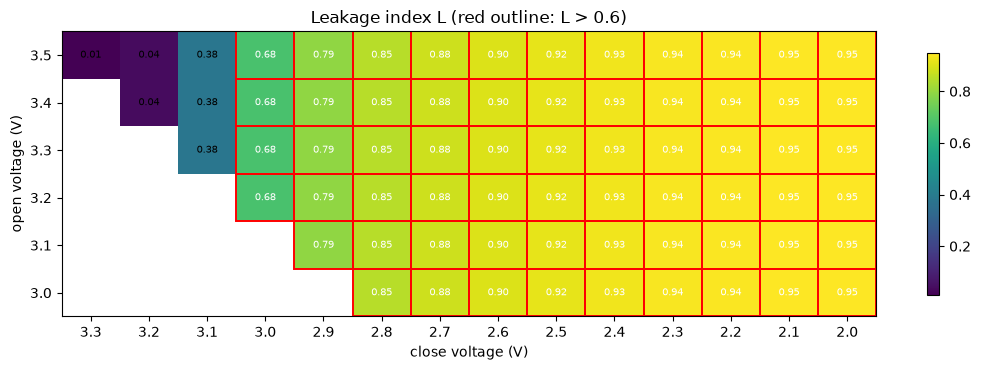

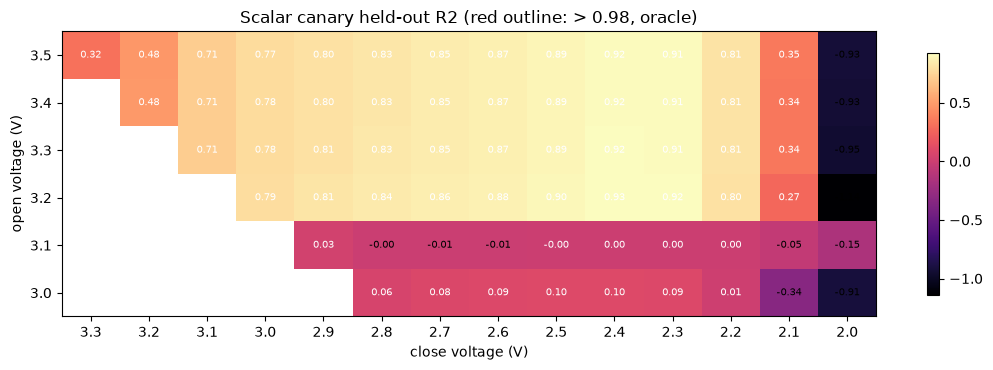

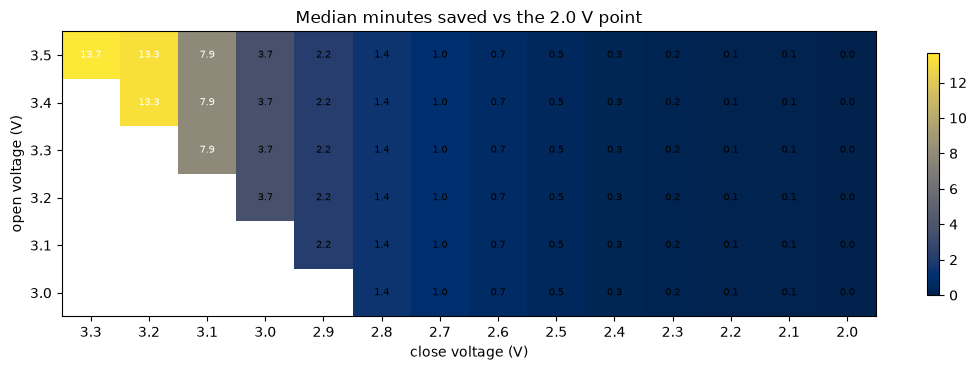

[PASS] window heatmaps written


In [15]:
with guard("7 window heatmaps"):
    def heat(col, title, fname, cmap, fmt, vmin=None, vmax=None, mark=None):
        M = np.full((len(WIN_OPENS), len(WIN_CLOSES)), np.nan)
        for _, r in WA[~WA.is_reference_full].iterrows():
            M[WIN_OPENS.index(r.open_v), WIN_CLOSES.index(r.close_v)] = r[col]
        fig, ax = plt.subplots(figsize=(11, 3.8))
        im = ax.imshow(np.ma.masked_invalid(M), cmap=cmap, aspect="auto", vmin=vmin, vmax=vmax)
        ax.set_xticks(range(len(WIN_CLOSES)), [f"{v:.1f}" for v in WIN_CLOSES])
        ax.set_yticks(range(len(WIN_OPENS)), [f"{v:.1f}" for v in WIN_OPENS])
        ax.set_xlabel("close voltage (V)"); ax.set_ylabel("open voltage (V)"); ax.set_title(title)
        for i in range(M.shape[0]):
            for j in range(M.shape[1]):
                if np.isfinite(M[i, j]):
                    ax.text(j, i, fmt(M[i, j]), ha="center", va="center", fontsize=7, color="white" if im.norm(M[i, j]) > 0.55 else "black")
        if mark is not None:
            for i in range(M.shape[0]):
                for j in range(M.shape[1]):
                    if np.isfinite(M[i, j]) and mark(M[i, j]):
                        ax.add_patch(plt.Rectangle((j - .5, i - .5), 1, 1, fill=False, ec="red", lw=1.4))
        fig.colorbar(im, ax=ax, shrink=0.85)
        fig.tight_layout(); fig.savefig(FIG / fname, dpi=130); plt.show(); plt.close(fig)

    heat("L", f"Leakage index L (red outline: L > {LATE_WINDOW_L})", "window_L_heatmap.png", "viridis", lambda x: f"{x:.2f}", mark=lambda x: x > LATE_WINDOW_L)
    heat("canary_r2", f"Scalar canary held-out R2 (red outline: > {CANARY_R2}, oracle)", "window_canary_r2_heatmap.png", "magma",
         lambda x: f"{x:.2f}", mark=lambda x: x > CANARY_R2)
    heat("minutes_saved_median", "Median minutes saved vs the 2.0 V point", "window_minutes_saved_heatmap.png", "cividis", lambda x: f"{x:.1f}")
    check("window heatmaps written", all((FIG / f).exists() for f in ["window_L_heatmap.png", "window_canary_r2_heatmap.png", "window_minutes_saved_heatmap.png"]))

## 8. Canaries and automated tests

Feature allow-list (with `assert_allowed`), split-leakage tests, a causality test on rewritten future rows, and the label identity test. A failing test is recorded as FAIL with details; every test runs.

In [16]:
def expect_raises(fn, exc=Exception):
    try:
        fn()
    except exc as e:
        return True, repr(e)
    return False, "no exception raised"

# ---- 8a feature allow-list
with guard("8a feature allow-list"):
    al = [{"column": k, **v} for k, v in sc.ALLOWLIST.items()]
    need = {"dq_window": "primary", "q0": "primary", "cycle_number": "ablation", "ir": "ablation", "chargetime": "ablation",
            "qd_sum": "label", "qd_end": "label", "qc_sum": "banned", "qc_end": "banned", "qd_lag1": None}
    miss = [k for k in need if k not in sc.ALLOWLIST]
    check("allow-list contains the required columns", not miss, str(miss))
    bad_role = [k for k, r in need.items() if r and sc.ALLOWLIST.get(k, {}).get("role") != r]
    check("allow-list roles as specified", not bad_role, str(bad_role))
    check("temperature fields are ablation-only", all(sc.ALLOWLIST[k]["role"] == "ablation" for k in ("tavg", "tmin", "tmax")))
    # correlation of the banned charge-side values with the label (scored dev rows)
    sd = D[D.scored & D.is_dev]
    corr = {c: float(np.corrcoef(sd[c][np.isfinite(sd[c])], sd.qd_sum[np.isfinite(sd[c])])[0, 1]) for c in ("qc_sum", "qc_end")}
    print("corr(qc, qd_sum) on scored development rows:", corr)
    meta = {"schema": "column -> role/available_at", "roles": ["primary", "ablation", "oracle", "banned", "label"],
            "default_allowed_roles_for_assert_allowed": ["primary", "ablation"],
            "banned_correlation_with_qd_sum": corr, "columns": al}
    (OUT / "feature_allowlist.json").write_text(json.dumps(meta, indent=2))
    ok1 = sc.assert_allowed(["dq_window", "q0", "cycle_number", "ir"])
    check("assert_allowed passes an allowed set", ok1 is True)
    ok2, d2 = expect_raises(lambda: sc.assert_allowed(["dq_window", "fake_column"]), ValueError)
    check("assert_allowed rejects an unknown column", ok2, d2)
    ok3, d3 = expect_raises(lambda: sc.assert_allowed(["dq_window", "qc_sum"]), ValueError)
    check("assert_allowed rejects a banned column", ok3, d3)

# ---- 8b split tests
with guard("8b split tests"):
    files = {"protocol_D": pd.read_csv(SPL / "protocol_D.csv"), "protocol_D_inner": pd.read_csv(SPL / "protocol_D_inner.csv"),
             "protocol_S": pd.read_csv(SPL / "protocol_S.csv"), "protocol_P": pd.read_csv(SPL / "protocol_P.csv")}
    locked = json.loads((SPL / "locked_test_cells.json").read_text())
    pol = CELLS.set_index("cell_id")["policy_norm"]
    # no cell in two roles of one fold
    dup = {}
    for name, keys in [("protocol_D", ["repeat", "outer_fold"]), ("protocol_D_inner", ["repeat", "outer_fold", "inner_fold"]), ("protocol_S", ["fold"])]:
        df = files[name]
        n_bad = int((df.groupby(keys + ["cell_id"]).role.nunique() > 1).sum()) + int(df.duplicated(keys + ["cell_id"]).sum())
        dup[name] = n_bad
    dup["protocol_P"] = int(files["protocol_P"].cell_id.duplicated().sum())
    check("no cell_id in two roles (or twice) within any fold", all(v == 0 for v in dup.values()), str(dup))

    # policy_norm never on both sides in D outer/inner folds
    def policy_leaks(df, keys, a, b):
        n = 0
        for _, g in df.groupby(keys):
            n += len(set(pol[g[g.role == a].cell_id]) & set(pol[g[g.role == b].cell_id]))
        return n
    lo = policy_leaks(files["protocol_D"], ["repeat", "outer_fold"], "train", "test")
    li = policy_leaks(files["protocol_D_inner"], ["repeat", "outer_fold", "inner_fold"], "train", "val")
    check("protocol D outer folds: no policy_norm on both sides", lo == 0, f"{lo} shared groups")
    check("protocol D inner folds: no policy_norm on both sides", li == 0, f"{li} shared groups")
    # inner folds stay inside the outer training set
    outer_train = files["protocol_D"][files["protocol_D"].role == "train"].groupby(["repeat", "outer_fold"]).cell_id.apply(set)
    inner_out = sum(len(set(g.cell_id) - outer_train[k[:2]]) for k, g in files["protocol_D_inner"].groupby(["repeat", "outer_fold", "inner_fold"]))
    check("inner folds only contain outer-training cells", inner_out == 0, f"{inner_out} stray cells")
    # coverage: every dev cell held out exactly once per repeat; 18 outer sets; 4 inner folds each
    cov = files["protocol_D"][files["protocol_D"].role == "test"].groupby(["repeat", "cell_id"]).size()
    check("each development cell is held out exactly once per repeat", bool((cov == 1).all()) and len(cov) == 3 * 84, f"{len(cov)} (repeat, cell) pairs")
    check("18 outer training sets x 4 inner folds", files["protocol_D"].groupby(["repeat", "outer_fold"]).ngroups == 18 and
          files["protocol_D_inner"].groupby(["repeat", "outer_fold"]).inner_fold.nunique().eq(4).all())

    # stitched cells are single groups; continuation ids absent everywhere; sensitivity absent; batch 3 absent from dev folds
    all_ids = set().union(*[set(df.cell_id) for df in files.values()])
    cont = {"b2c7", "b2c8", "b2c9", "b2c15", "b2c16"}
    check("continuation cell ids appear in no split", not (cont & all_ids), str(sorted(cont & all_ids)))
    check("sensitivity cells appear in no split", not (SENS_IDS & all_ids), str(sorted(SENS_IDS & all_ids)))
    stitched = ["b1c0", "b1c1", "b1c2", "b1c3", "b1c4"]
    check("each stitched cell has exactly one policy group", all(pd.Series([pol[c]]).nunique() == 1 for c in stitched))
    one_role = all(files["protocol_D"][files["protocol_D"].cell_id == c].groupby(["repeat", "outer_fold"]).role.nunique().max() == 1 for c in stitched)
    check("stitched cells never split across roles", one_role)
    b3_ids = set(CELLS[CELLS.batch == 3].cell_id)
    leak_dev = (b3_ids & set(files["protocol_D"].cell_id)) | (b3_ids & set(files["protocol_D_inner"].cell_id))
    ps = files["protocol_S"]
    leak_dev |= b3_ids & set(ps[ps.fold.isin(["b1", "b2"])].cell_id) | (b3_ids & set(ps[(ps.fold == "b3") & (ps.role == "train")].cell_id))
    check("no batch-3 cell in any development fold", not leak_dev, str(sorted(leak_dev)))
    check("locked test list = 40 batch-3 kept cells, hash verifies",
          set(locked["cells"]) == b3_ids and len(locked["cells"]) == 40 and
          hashlib.sha256("\n".join(sorted(locked["cells"])).encode()).hexdigest() == locked["sha256_sorted_list"])
    check("protocol S b3 locked_test equals locked list", set(ps[ps.role == "locked_test"].cell_id) == set(locked["cells"]))
    check("protocol D covers exactly the 84 development cells", set(files["protocol_D"].cell_id) == set(CELLS[CELLS.is_dev].cell_id))
    check("protocol P covers exactly the 124 kept cells", set(files["protocol_P"].cell_id) == set(CELLS.cell_id))
    # dev cells with at least one scored row (a cell with none cannot be evaluated)
    n_sc = D[D.scored & D.is_dev].groupby("cell_id").size().reindex(CELLS[CELLS.is_dev].cell_id).fillna(0)
    warn_if("every development cell has scored rows", bool((n_sc > 0).all()), f"no scored rows: {n_sc[n_sc == 0].index.tolist()}")

[PASS] allow-list contains the required columns -- []
[PASS] allow-list roles as specified -- []
[PASS] temperature fields are ablation-only
corr(qc, qd_sum) on scored development rows: {'qc_sum': 0.9998266754597394, 'qc_end': 0.9998266756466274}
[PASS] assert_allowed passes an allowed set
[PASS] assert_allowed rejects an unknown column -- ValueError("disallowed input columns: unknown=['fake_column'] wrong_role=[]")
[PASS] assert_allowed rejects a banned column -- ValueError("disallowed input columns: unknown=[] wrong_role=['qc_sum']")
[PASS] no cell_id in two roles (or twice) within any fold -- {'protocol_D': 0, 'protocol_D_inner': 0, 'protocol_S': 0, 'protocol_P': 0}
[PASS] protocol D outer folds: no policy_norm on both sides -- 0 shared groups
[PASS] protocol D inner folds: no policy_norm on both sides -- 0 shared groups
[PASS] inner folds only contain outer-training cells -- 0 stray cells
[PASS] each development cell is held out exactly once per repeat -- 252 (repeat, cell) pairs
[

In [17]:
def recompute_reference_from_arrays(cyc, qdl, qds, fl_causal):
    """Section-4 definition applied to copied arrays: returns (n_ref, ref_last, q0, qref, ok_mask)."""
    fin = np.isfinite(qdl).all(axis=1)
    safe = np.where(fin[:, None], qdl, 0.0)
    md = np.diff(safe, axis=1).min(axis=1)
    q_ok = fin & (md >= -MONO_TOL) & (np.abs(qdl[:, 0]) <= Q0_TOL)
    ok = q_ok & (~fl_causal) & np.isfinite(qds)
    sel = pick_reference(cyc, ok)
    if len(sel) < REF_N:
        return len(sel), np.nan, np.nan, None, ok
    return len(sel), float(cyc[sel].max()), float(np.median(qds[sel])), np.median(qdl[sel].astype(np.float32), axis=0).astype(np.float32), ok

with guard("8c causality test"):
    pick = [CELLS[CELLS.batch == b].cell_id.iloc[0] for b in (1, 2, 3)]
    rng = np.random.default_rng(SEED)
    CAUSAL_ROWS = []
    for c in pick:
        rows = CELL_ROWS[c]
        cyc = D["cycle_number"].to_numpy(float)[rows]
        blk_sorted = np.asarray(qd[np.sort(rows)], dtype=np.float32)   # memmap fancy index needs ascending rows
        base_q = blk_sorted[np.argsort(np.argsort(rows))]               # restore CELL_ROWS (cycle) order
        base_s = D["qd_sum"].to_numpy(float)[rows]
        base_f = (D.flag_placeholder | D.flag_qdlin_bad | D.flag_diag_suspect | D.flag_qd_mismatch).to_numpy()[rows]
        n0, rl0, q00, qr0, _ = recompute_reference_from_arrays(cyc, base_q, base_s, base_f)
        check(f"causality baseline reference exists for {c}", n0 == REF_N and qr0 is not None, f"ref_last={rl0}")
        ref_row = CREF.set_index("cell_id").loc[c]
        check(f"recomputed Q0/ref_last equal section 4 for {c}", np.isclose(q00, ref_row.q0) and rl0 == ref_row.ref_last, f"{q00} vs {ref_row.q0}")
        i_o, i_c = gidx(3.5), gidx(3.0)
        for k in (rl0, rl0 + 50, rl0 + 300):
            keep = cyc <= k
            qm, sm, fm = base_q.copy(), base_s.copy(), base_f.copy()
            fut = ~keep
            qm[fut] = rng.uniform(-5, 5, size=(int(fut.sum()), 1000)).astype(np.float32)
            sm[fut] = rng.uniform(0, 3, size=int(fut.sum()))
            fm[fut] = rng.random(int(fut.sum())) < 0.5
            n1, rl1, q01, qr1, _ = recompute_reference_from_arrays(cyc, qm, sm, fm)
            same = (n1 == n0) and rl1 == rl0 and np.isclose(q01, q00, rtol=0, atol=0) and np.array_equal(qr1, qr0)
            kk = np.flatnonzero(keep)[-1]                                   # last row at or before k
            cap0 = base_q[kk, i_c] - base_q[kk, i_o]; cap1 = qm[kk, i_c] - qm[kk, i_o]
            dq0 = sc.build_delta_q(base_q[kk], qr0, i_o, i_c); dq1 = sc.build_delta_q(qm[kk], qr1, i_o, i_c)
            same &= bool(cap0 == cap1) and np.array_equal(dq0, dq1)
            check(f"causality {c} k={int(k)}: Q0, Qref, window capacity, delta-Q unchanged", same,
                  f"n_ref={n1}, ref_last={rl1}, cap {cap0:.6f}/{cap1:.6f}")
            CAUSAL_ROWS.append(dict(cell_id=c, k=int(k), unchanged=bool(same)))
        # before the reference is complete the reference is simply not available
        k_early = rl0 - 1
        keep = cyc <= k_early
        n_e, rl_e, q0_e, qr_e, _ = recompute_reference_from_arrays(cyc[keep], base_q[keep], base_s[keep], base_f[keep])
        check(f"{c}: reference unavailable for k={int(k_early)} < ref_last", qr_e is None and n_e < REF_N, f"only {n_e} usable reference cycles")
    save_csv(pd.DataFrame(CAUSAL_ROWS), "causality_test.csv")

with guard("8d label identity and canary helper"):
    LT2 = pd.read_parquet(PROC / "labels_table.parquet")
    chk = LT2[LT2.scored].merge(cycles[["row_id", "qd_sum"]], on="row_id", how="left")
    maxdiff = float(np.max(np.abs(chk["soh_nom"].to_numpy() * 1.1 - chk["qd_sum"].to_numpy())))
    # soh_nom = qd_sum / 1.1 in float64; (x / 1.1) * 1.1 can differ from x by 1 ulp, so exact zero is not representable
    check("label identity: soh_nom * 1.1 == qd_sum on all scored rows (<= 1e-12 Ah, i.e. float64 round-off)", maxdiff <= 1e-12, f"max abs diff {maxdiff:.3e}")
    check("shuffle_labels_within_cell is defined (not run)", callable(sc.shuffle_labels_within_cell))
    # soh_nom_repaired differs from soh_nom only on label_suspect rows
    d_rep = LT2[(LT2.soh_nom_repaired != LT2.soh_nom) & ~LT2.soh_nom.isna()]
    check("repaired labels differ only on label_suspect rows", bool(d_rep.label_suspect.all()), f"{len(d_rep)} changed rows")
    check("scored rows never include label_suspect", not bool((LT2.scored & LT2.label_suspect).any()))
    check("scored rows respect score_start and in_life", bool((LT2[LT2.scored].cycle_number >= LT2[LT2.scored].score_start).all()
                                                              and LT2[LT2.scored].in_life.all()))

[PASS] causality baseline reference exists for b1c0 -- ref_last=13.0
[PASS] recomputed Q0/ref_last equal section 4 for b1c0 -- 1.0744922 vs 1.0744922
[PASS] causality b1c0 k=13: Q0, Qref, window capacity, delta-Q unchanged -- n_ref=5, ref_last=13.0, cap 0.833805/0.833805
[PASS] causality b1c0 k=63: Q0, Qref, window capacity, delta-Q unchanged -- n_ref=5, ref_last=13.0, cap 0.844611/0.844611
[PASS] causality b1c0 k=313: Q0, Qref, window capacity, delta-Q unchanged -- n_ref=5, ref_last=13.0, cap 0.813576/0.813576
[PASS] b1c0: reference unavailable for k=12 < ref_last -- only 4 usable reference cycles
[PASS] causality baseline reference exists for b2c0 -- ref_last=12.0
[PASS] recomputed Q0/ref_last equal section 4 for b2c0 -- 1.0730482 vs 1.0730482
[PASS] causality b2c0 k=12: Q0, Qref, window capacity, delta-Q unchanged -- n_ref=5, ref_last=12.0, cap 0.819830/0.819830
[PASS] causality b2c0 k=62: Q0, Qref, window capacity, delta-Q unchanged -- n_ref=5, ref_last=12.0, cap 0.743564/0.743564


## 9. QD versus QC and corrected decomposition

Scored development rows only, no model. Baseline B5 (oracle group) uses `qc_sum / 1.1` directly as the predictor of `qd_sum / 1.1`. The decomposition is recomputed on in-life rows only; batch-2 rows after end of life form a separate extrapolation table.

In [18]:
WCLOSE = (3.0, 2.5, 2.0)

with guard("9 QD vs QC"):
    sd_mask = (D.scored & D.is_dev).to_numpy()
    S9 = D.loc[sd_mask, ["cell_id", "batch", "qd_sum", "qc_sum", "qd_end", "qc_end"]].reset_index(drop=True)
    Q9 = QCMP[np.flatnonzero(sd_mask)]
    for cv in WCLOSE:
        S9[f"w_{cv}"] = Q9[:, CMAP[gidx(cv)]].astype(float) - Q9[:, CMAP[0]].astype(float)
    rows9 = []
    for label, sub in [("batch1", S9[S9.batch == 1]), ("batch2", S9[S9.batch == 2]), ("all dev", S9)]:
        sub = sub[np.isfinite(sub.qc_sum) & np.isfinite(sub.qd_sum)]
        y, p = sub.qd_sum / NOMINAL_AH, sub.qc_sum / NOMINAL_AH               # baseline B5: identity predictor, no fit
        r2 = 1 - np.sum((y - p) ** 2) / np.sum((y - y.mean()) ** 2)
        mae = (y - p).abs().groupby(sub.cell_id).mean().mean() * 100
        rec = dict(subset=label, n_rows=len(sub), n_cells=sub.cell_id.nunique(), pearson_qc_qd=float(np.corrcoef(sub.qc_sum, sub.qd_sum)[0, 1]),
                   b5_r2=float(r2), b5_cell_macro_mae_pp=float(mae), group="oracle (baseline B5)")
        sub2 = sub[np.isfinite(sub.qd_end) & np.isfinite(sub.qc_end)]
        rec["pearson_qcend_qdend"] = float(np.corrcoef(sub2.qc_end, sub2.qd_end)[0, 1])
        for cv in WCLOSE:
            w = sub[f"w_{cv}"]
            rec[f"corr_w{cv}_qd_sum"] = float(np.corrcoef(w, sub.qd_sum)[0, 1])
            rec[f"med_w{cv}_over_qd_end"] = float((w / sub.qd_end).median())
            rec[f"corr_w{cv}_over_qdend_soh"] = float(np.corrcoef(w / sub.qd_end, sub.qd_sum / NOMINAL_AH)[0, 1])
        rows9.append(rec)
    T9 = pd.DataFrame(rows9)
    save_csv(T9, "qd_vs_qc.csv")
    print(T9.T.to_string(header=False, float_format=lambda x: f"{x:.4f}"))

with guard("9 decomposition in life"):
    ml = (D.in_life & D.is_kept & D.qdlin_ok & np.isfinite(D.qd_end) & (D.qd_end > 0)).to_numpy()
    ix = np.flatnonzero(ml)
    X = D.loc[ml, ["cell_id", "batch", "life", "qd_end", "qd_sum"]].reset_index(drop=True)
    QX, TX = QCMP[ix], tk[ix].astype(float)
    dev_life = CELLS[CELLS.is_dev].life.to_numpy()
    dec_cuts = np.quantile(dev_life, np.linspace(0.1, 0.9, 9))              # deciles from development cells only
    X["life_decile"] = np.digitize(X.life.to_numpy(), dec_cuts) + 1
    for cv in WCLOSE:
        X[f"wc_{cv}"] = (QX[:, CMAP[gidx(cv)]].astype(float) - QX[:, CMAP[0]].astype(float)) / X.qd_end
    X["qd_cv_tail_over_qd_end"] = (X.qd_end - QX[:, CMAP[999]].astype(float)) / X.qd_end       # capacity delivered after the 2.0 V grid end
    k20 = KNOT_V.index(2.0)
    X["duration_to_2.0V_min"] = TX[:, k20]
    for cv in WCLOSE:
        X[f"min_saved_close_{cv}"] = TX[:, k20] - TX[:, KNOT_V.index(cv)]
    metrics = [c for c in X.columns if c.startswith(("wc_", "qd_cv_tail", "duration", "min_saved"))]
    outs = []
    for key in ("batch", "life_decile"):
        g = X.groupby(key)[metrics].median()
        g.insert(0, "n_rows", X.groupby(key).size()); g.insert(0, "n_cells", X.groupby(key).cell_id.nunique())
        g.insert(0, "by", key); g = g.reset_index().rename(columns={key: "level"})
        outs.append(g)
    allrow = X[metrics].median().to_frame().T
    allrow.insert(0, "n_rows", len(X)); allrow.insert(0, "n_cells", X.cell_id.nunique()); allrow.insert(0, "level", "all"); allrow.insert(0, "by", "all")
    T9b = pd.concat(outs + [allrow], ignore_index=True)
    save_csv(T9b, "decomposition_in_life.csv")
    print("note: qd_cv_tail is taken as qd_end minus Qdlin[2.0 V], i.e. the share of discharge capacity after the linear grid end.")
    print(T9b.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

with guard("9 post-EOL batch 2"):
    pe = D[(D.batch == 2) & D.is_kept & (~D.ph) & (D.cycle_number > D.life)]
    T9c = pe.groupby("cell_id").agg(n_rows=("row_id", "size"), first_cycle=("cycle_number", "min"), last_cycle=("cycle_number", "max"),
                                    life=("life", "first"), qd_min=("qd_sum", "min"), qd_max=("qd_sum", "max"),
                                    n_qdlin_ok=("qdlin_ok", "sum"), n_causal_ok=("causal_ok", "sum"),
                                    n_label_suspect=("label_suspect", "sum")).reset_index()
    T9c["qd_min_soh"] = T9c.qd_min / NOMINAL_AH; T9c["qd_max_soh"] = T9c.qd_max / NOMINAL_AH
    save_csv(T9c, "post_eol_batch2.csv")
    print(f"batch-2 post-EOL rows: {len(pe)} in {len(T9c)} cells; per-cell count median {T9c.n_rows.median():.0f}, range {T9c.n_rows.min()}-{T9c.n_rows.max()} "
          f"(expected 20-37 past life); QD range {pe.qd_sum.min():.3f}-{pe.qd_sum.max():.3f} Ah")
    warn_if("post-EOL rows per cell within 20-37", bool(T9c.n_rows.between(20, 37).all()) if len(T9c) else False,
            f"outside: {T9c[~T9c.n_rows.between(20, 37)].cell_id.tolist()}" if len(T9c) else "no rows")
    warn_if("post-EOL rows are excluded from scored", not bool(D.loc[pe.index, "scored"].any()))

subset                                  batch1                batch2               all dev
n_rows                                   36717                 19248                 55965
n_cells                                     41                    43                    84
pearson_qc_qd                           0.9998                0.9999                0.9998
b5_r2                                   0.9996                0.9996                0.9996
b5_cell_macro_mae_pp                    0.0409                0.0563                0.0488
group                     oracle (baseline B5)  oracle (baseline B5)  oracle (baseline B5)
pearson_qcend_qdend                     0.9998                0.9999                0.9998
corr_w3.0_qd_sum                        0.9047                0.9354                0.8861
med_w3.0_over_qd_end                    0.7215                0.6628                0.7062
corr_w3.0_over_qdend_soh                0.7314                0.8778                0.7388

## 10. Shared module and report

Writes `src/soh_common.py` (same source as the in-notebook module, re-imported and cross-checked), the text and JSON reports, the artifact hashes, and prints the final compact report block.

In [19]:
import importlib.util

with guard("10 write soh_common.py"):
    (SRC / "soh_common.py").write_text(SOH_COMMON_SRC)
    spec = importlib.util.spec_from_file_location("soh_common_disk", SRC / "soh_common.py")
    sd_mod = importlib.util.module_from_spec(spec); spec.loader.exec_module(sd_mod)
    check("soh_common.py imports from disk", True, str(SRC / "soh_common.py"))
    check("soh_common constants match notebook config",
          (sd_mod.SEED, sd_mod.NOMINAL_AH, sd_mod.EOL_AH, sd_mod.REF_FIRST_CYCLE, sd_mod.REF_N, sd_mod.SCORE_GAP, sd_mod.MIN_SCORE_CYCLE,
           sd_mod.CANARY_R2, sd_mod.LATE_WINDOW_L) ==
          (SEED, NOMINAL_AH, EOL_AH, REF_FIRST_CYCLE, REF_N, SCORE_GAP, MIN_SCORE_CYCLE, CANARY_R2, LATE_WINDOW_L))
    check("grid_index: 3.5/3.0/2.0 -> 0/333/999", (sd_mod.grid_index(3.5), sd_mod.grid_index(3.0), sd_mod.grid_index(2.0)) == (0, 333, 999))
    sl = sd_mod.window_slice(3.5, 3.0)
    check("window_slice(3.5, 3.0) spans 334 points", (sl.start, sl.stop) == (0, 334), str(sl))
    ok_err, d_err = expect_raises(lambda: sd_mod.window_slice(3.0, 3.5), ValueError)
    check("window_slice rejects close above open", ok_err, d_err)
    cells_t, qd_t, tk_t, reg_t2 = sd_mod.load_tables(ROOT)
    check("load_tables returns the Phase 2 shapes", (len(cells_t), qd_t.shape, tk_t.shape) == (len(cycles), qd.shape, tk.shape))
    row_t = np.asarray(qd[1000], dtype=np.float32); ref_t = QREF[0]
    check("build_delta_q identical in notebook and on-disk module",
          np.array_equal(sd_mod.build_delta_q(row_t, ref_t, 0, 333), sc.build_delta_q(row_t, ref_t, 0, 333)))
    dq = sd_mod.build_delta_q(row_t, ref_t, 0, 333)
    check("build_delta_q starts at 0 and has window width", dq.shape == (334,) and dq[0] == 0, str(dq.shape))
    check("build_delta_q 32-point subsample", sd_mod.build_delta_q(row_t, ref_t, 0, 333, n_points=32).shape == (32,))
    del cells_t, qd_t, tk_t, reg_t2

with guard("10 reports"):
    RT = time.time() - T0
    art_names = [SPL / f for f in sorted(os.listdir(SPL))]
    hashes_art = {str(p.relative_to(ROOT)).replace("\\", "/"): sha256_file(p) for p in art_names}
    (OUT / "artifact_hashes.json").write_text(json.dumps(hashes_art, indent=2))
    check("artifact_hashes.json covers every split file and the locked list", "data/processed/splits/locked_test_cells.json" in hashes_art and len(hashes_art) == 5, f"{len(hashes_art)} files (4 protocol csv + locked list)")

def g(name, default=None):
    return globals().get(name, default)

def fmt_ranges_table(df, cols, n=8):
    return "" if df is None or len(df) == 0 else df[cols].head(n).to_string(index=False)

[PASS] soh_common.py imports from disk -- c:\workstation\3RD YEAR\Battery-Health-Estimation\src\soh_common.py
[PASS] soh_common constants match notebook config
[PASS] grid_index: 3.5/3.0/2.0 -> 0/333/999
[PASS] window_slice(3.5, 3.0) spans 334 points -- slice(0, 334, None)
[PASS] window_slice rejects close above open -- ValueError('close voltage must be below open voltage')
[PASS] load_tables returns the Phase 2 shapes
[PASS] build_delta_q identical in notebook and on-disk module
[PASS] build_delta_q starts at 0 and has window width -- (334,)
[PASS] build_delta_q 32-point subsample
[PASS] artifact_hashes.json covers every split file and the locked list -- 5 files (4 protocol csv + locked list)


In [20]:
L_ = []
def add(s=""):
    L_.append(s)

with guard("10 report text"):
    RT = time.time() - T0
    add("PHASE 3 REPORT")
    add("=" * 78)
    add(f"runtime: {RT/60:.1f} min | seed {SEED} | rows {len(cycles)} | cells {len(tab_cells)} (kept {len(KEPT_IDS)}, sensitivity {len(SENS_IDS)})")
    add("")
    add("[2] TRIAGE HIGHLIGHTS")
    fb_ = g("fb")
    if fb_ is not None:
        add(f"  flag_qdlin_bad: {len(fb_)} rows / {fb_.cell_id.nunique()} cells; per batch {fb_.groupby('batch').size().to_dict()}; "
            f"<=life & >=20: {int((fb_.le_life & fb_.ge20).sum())}; nonfinite {int(fb_.nonfinite.sum())}, nonmono {int(fb_.nonmono.sum())}, "
            f"q0-out {int(fb_.q0out.sum())}; overlap qd_mismatch {int(fb_.flag_qd_mismatch.sum())}, diag_suspect {int(fb_.flag_diag_suspect.sum())}")
    t2b_ = g("t2b")
    if t2b_ is not None:
        r = t2b_[(t2b_.rows == "all non-placeholder") & t2b_.metric.str.startswith("Qdlin[0]")].iloc[0]
        r2_ = t2b_[(t2b_.rows == "excluding flag_qdlin_bad") & t2b_.metric.str.startswith("Qdlin[0]")].iloc[0]
        add(f"  Qdlin[0] range all rows {r.q000:.3f}..{r.q100:.3f}; after excluding flag_qdlin_bad {r2_.q000:.4f}..{r2_.q100:.4f}")
    t2c_ = g("t2c")
    if t2c_ is not None:
        a = t2c_[(t2c_.batch == "all")]
        for _, rr in a.iterrows():
            add(f"  {rr.variable}: >1e-2: {int(rr['1e-2..0.1'] + rr['0.1..1.0'] + rr['>1.0'])}, >1.0: {int(rr['>1.0'])} of {int(rr.n)}")
    cs_ = g("cs")
    if cs_ is not None:
        add(f"  batch-2 246-258 event: {len(cs_)} cells; most shared cycles {g('top_c')[['cycle_number','n_cells']].values.tolist() if g('top_c') is not None else ''}")
    add(f"  diagnostics: {g('DIAG_STATEMENT', 'n/a')}")
    t2f_ = g("bad")
    if t2f_ is not None:
        add(f"  reference window 8-12 flagged in {len(t2f_)} cells: " + ", ".join(t2f_.cell_id.head(14)) + (" ..." if len(t2f_) > 14 else ""))
    add("")
    add("[3] MASK COUNTS (rows)")
    if g("t3") is not None:
        add("  " + g("t3").to_string().replace("\n", "\n  "))
    add("")
    add("[4] Q0 / SCORE START")
    if g("q0b") is not None:
        add("  Q0 per batch (kept): " + "; ".join(f"b{int(b)} median {r['median']:.4f} range {r['min']:.4f}-{r['max']:.4f}" for b, r in g("q0b").iterrows()))
    cr_ = CREF[CREF.status == "kept"]
    add(f"  score_start: median {cr_.score_start.median():.0f}, max {cr_.score_start.max():.0f}; cells with score_start > 20: {int((CREF.score_start > 20).sum())}")
    add(f"  scored rows: {int(D.scored.sum())} (development {int((D.scored & D.is_dev).sum())}); lost mask counts {g('lost')}")
    nd = CREF[CREF.ref_differs_from_8_12]
    add(f"  cells with non-default reference ({len(nd)}): " + "; ".join(f"{r.cell_id} [{r.ref_cycles}]" for r in nd.itertuples()))
    add("")
    add("[5] POLICY GROUPS")
    add(f"  {g('POLICY_COUNTS')}; life tertile cuts (dev only) {g('LIFE_CUTS')}")
    add("")
    add("[6] SPLITS")
    if g("SREP") is not None:
        d = SREP[SREP.protocol == "D"]
        add(f"  D: 18 outer sets (test cells {d[d.role=='test'].n_cells.min()}-{d[d.role=='test'].n_cells.max()}), 72 inner folds; policy overlap train/test: outer {g('lo')}, inner {g('li')}")
        s_ = SREP[SREP.protocol == "S"]
        add("  S: " + "; ".join(f"{r.fold}/{r.role} n={r.n_cells}" for r in s_.itertuples()))
        pl = g("PS_overlap")
    if g("PS") is not None:
        ov = []
        for fo in ("b1", "b2", "b3"):
            trn = set(pol[PS[(PS.fold == fo) & (PS.role == "train")].cell_id]); tst = set(pol[PS[(PS.fold == fo) & (PS.role != "train")].cell_id])
            ov.append(f"{fo}: {len(trn & tst)} shared policy strings")
        add("  S policy overlap (train vs test): " + "; ".join(ov))
    add(f"  P: {g('P_OVERLAP')}")
    add("")
    add("[7] WINDOW AUDIT")
    if len(WA):
        cand = WA[~WA.is_reference_full]
        best = cand.loc[cand.canary_r2.idxmax()]
        add(f"  windows {len(cand)}: oracle {int(cand.oracle.sum())}, late {int(cand.late_window.sum())}, open {int(((~cand.oracle) & (~cand.late_window)).sum())}; best canary R2 {best.canary_r2:.4f} at {best.open_v}->{best.close_v} V")
        f_ = WA[WA.is_reference_full].iloc[0]
        add(f"  full 3.5->2.0: L {f_.L:.3f}, R2 {f_.canary_r2:.4f}, MAE {f_.canary_mae_pp:.2f} pp")
        low = cand[~cand.oracle].sort_values("L").head(10)
        add("  10 lowest-L windows that are not oracle:")
        add("    " + low[["open_v", "close_v", "width_pts", "L", "canary_r2", "canary_mae_pp", "minutes_saved_median"]].to_string(index=False, float_format=lambda x: f"{x:.3f}").replace("\n", "\n    "))
    add("")
    add("[8-10] CHECKS")
    for st in ("FAIL", "WARN", "PASS"):
        sel = [c for c in CHECKS if c["status"] == st]
        add(f"  {st} ({len(sel)})")
        for c in sel:
            add(f"    - {c['name']}" + (f": {c['detail'][:160]}" if st != "PASS" and c["detail"] else ""))
    add("")
    add(f"ERRORS ({len(ERRORS)})")
    for e in ERRORS:
        add(f"  [{e['section']}] {e['error']}")
    add("")
    add("ARTIFACTS")
    arts = [PROC / "labels_table.parquet", PROC / "cell_reference.csv", PROC / "qref_f32.npy", PROC / "qref_cell_ids.csv", SRC / "soh_common.py"] \
         + sorted(SPL.glob("*")) + sorted(OUT.glob("*.*")) + sorted(FIG.glob("*.png"))
    for p in arts:
        if p.exists() and p.name not in ("phase3_report.txt", "verification_report.json"):
            add(f"  {str(p.relative_to(ROOT)).replace(chr(92), '/'):58s} {p.stat().st_size/1024:10.1f} KiB")
    add("  outputs/phase3/phase3_report.txt, outputs/phase3/verification_report.json (this report)")
    REPORT = "\n".join(L_)
    (OUT / "phase3_report.txt").write_text(REPORT)
    n_f = sum(c["status"] == "FAIL" for c in CHECKS)
    (OUT / "verification_report.json").write_text(json.dumps({
        "runtime_s": RT, "seed": SEED, "n_checks": len(CHECKS), "n_pass": sum(c["status"] == "PASS" for c in CHECKS),
        "n_warn": sum(c["status"] == "WARN" for c in CHECKS), "n_fail": n_f, "checks": CHECKS,
        "errors": [{"section": e["section"], "error": e["error"]} for e in ERRORS],
        "config": dict(SEED=SEED, NOMINAL_AH=NOMINAL_AH, EOL_AH=EOL_AH, REF_FIRST_CYCLE=REF_FIRST_CYCLE, REF_N=REF_N,
                       SCORE_GAP=SCORE_GAP, MIN_SCORE_CYCLE=MIN_SCORE_CYCLE, CANARY_R2=CANARY_R2, LATE_WINDOW_L=LATE_WINDOW_L)}, indent=2, default=str))

print(REPORT if "REPORT" in globals() else "PHASE 3 REPORT\nreport generation failed; see ERRORS: " + str([e["error"] for e in ERRORS]))

PHASE 3 REPORT
runtime: 1.1 min | seed 42 | rows 104971 | cells 129 (kept 124, sensitivity 5)

[2] TRIAGE HIGHLIGHTS
  flag_qdlin_bad: 289 rows / 44 cells; per batch {1: 46, 2: 239, 3: 4}; <=life & >=20: 282; nonfinite 0, nonmono 289, q0-out 3; overlap qd_mismatch 3, diag_suspect 3
  Qdlin[0] range all rows -4.488..30.732; after excluding flag_qdlin_bad -4.4879..0.0001
  |qd_end-qd_sum|: >1e-2: 166, >1.0: 27 of 104925
  |qc_end-qc_sum|: >1e-2: 128, >1.0: 27 of 104925
  batch-2 246-258 event: 21 cells; most shared cycles [[247, 5], [248, 5], [250, 4]]
  diagnostics: No C/10 diagnostic cycles at cycle numbers 1,2,3,100,101 (current and sample count normal).
  reference window 8-12 flagged in 9 cells: b1c0, b1c1, b1c2, b1c3, b1c4, b1c10, b1c11, b1c18, b1c41

[3] MASK COUNTS (rows)
           rows  placeholder  in_life  qdlin_ok  causal_ok  label_suspect  post_junction
  batch                                                                                 
  1       42204           46    4